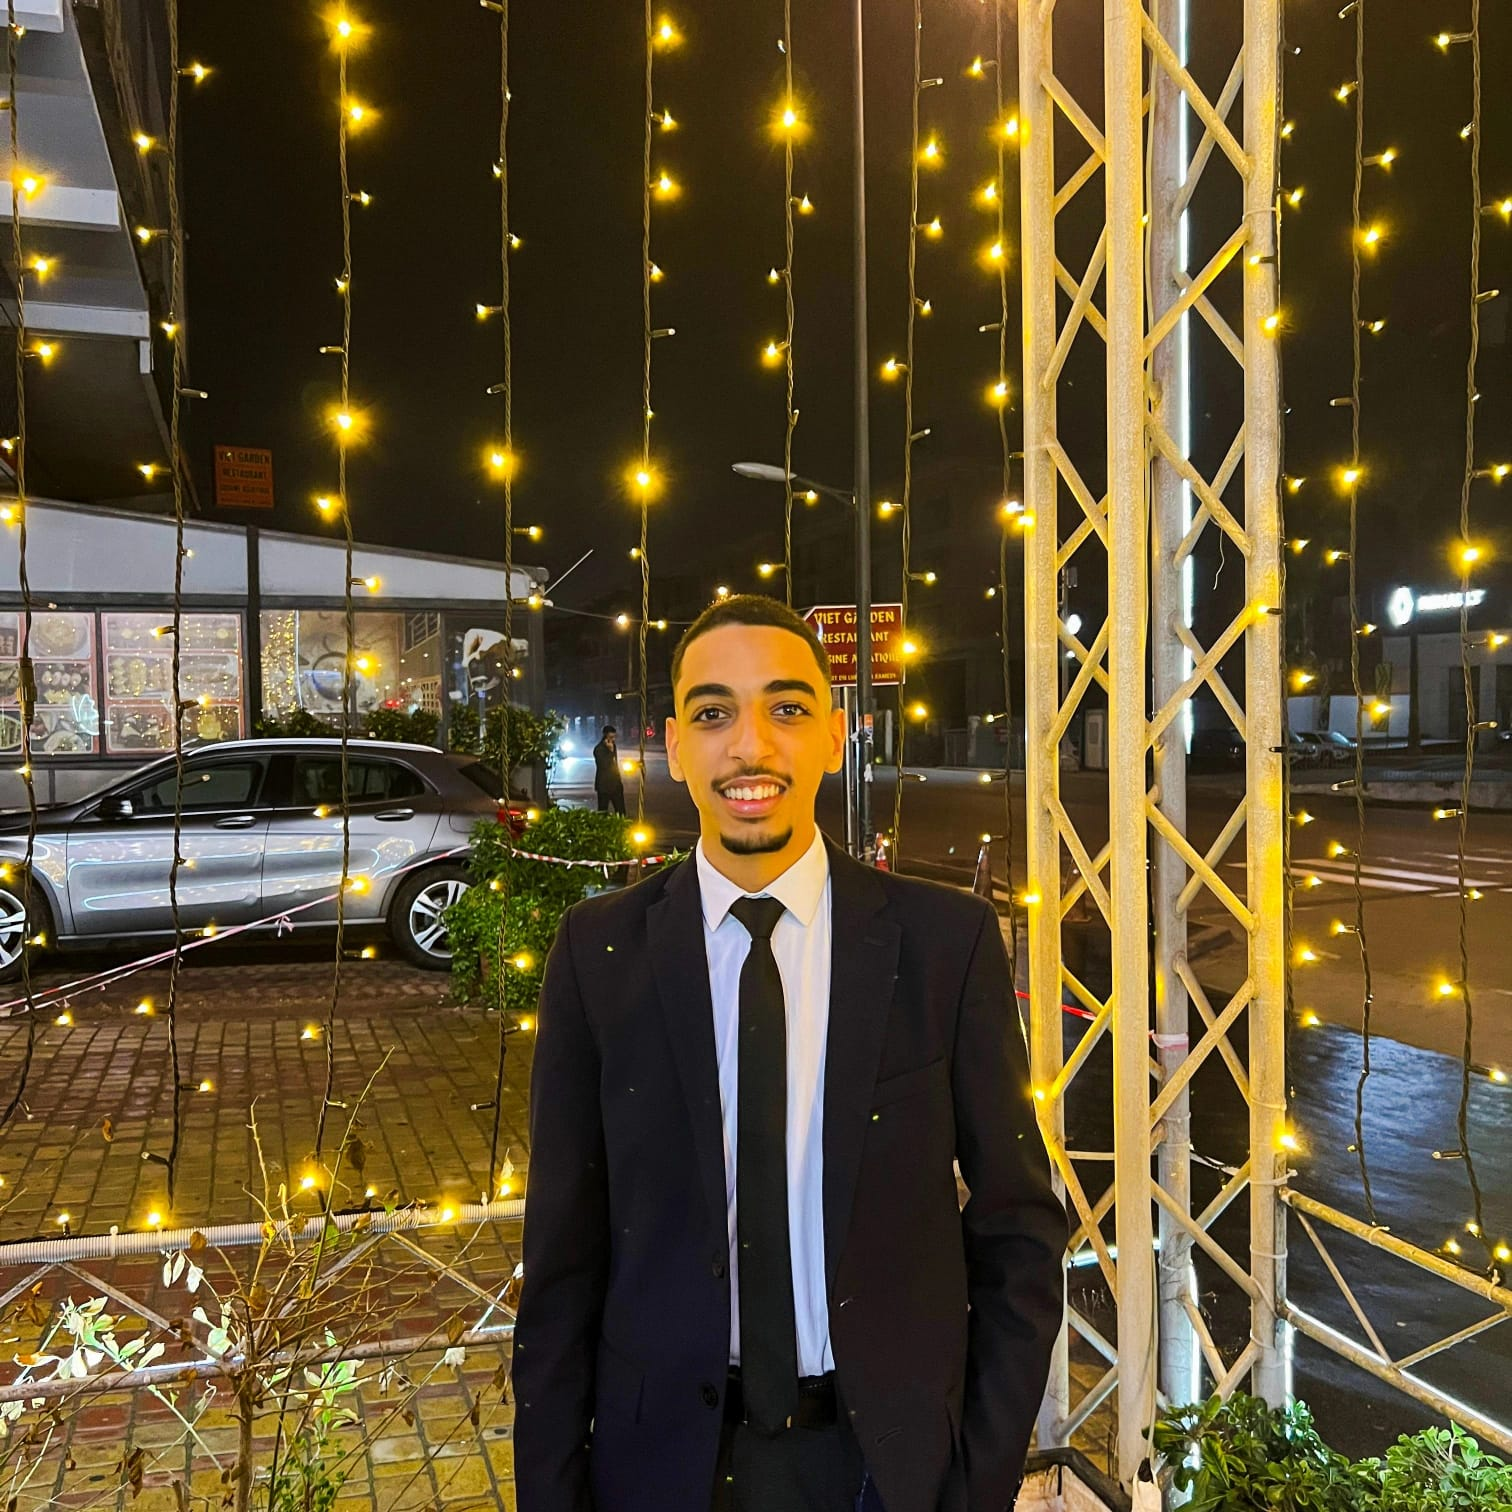

https://colab.research.google.com/assets/colab-badge.svg)](https://github.com/anasschahide05-tech/25007861-Anass-CHAHID/blob/5e434da4e31348f308cbc6a7779e2b4c5c14d685/CC_Anass_CHAHID.ipynb)

Anass CHAHID S7 CI 2026/2027

In [1]:
!pip -q install -U scikit-learn xgboost umap-learn gymnasium

In [2]:
# Sources réelles intégrées à scikit-learn : trois problèmes différents
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, roc_auc_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
GRAINE = 42

jeu_regression = load_diabetes()
X_reg, y_reg = jeu_regression.data, jeu_regression.target
jeu_classification = load_breast_cancer()
X_cls, y_cls = jeu_classification.data, jeu_classification.target
jeu_non_supervise = load_wine()
X_clu = StandardScaler().fit_transform(jeu_non_supervise.data)  # Exploration sans cible

Xr_ent, Xr_test, yr_ent, yr_test = train_test_split(X_reg, y_reg, test_size=.25, random_state=GRAINE)
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X_cls, y_cls, test_size=.25, stratify=y_cls, random_state=GRAINE)
print('Diabetes:', X_reg.shape, '| Breast Cancer:', X_cls.shape, '| Wine:', X_clu.shape)
print('Ces données sont réelles ; les étiquettes du vin ne sont pas employées dans le clustering.')


Diabetes: (442, 10) | Breast Cancer: (569, 30) | Wine: (178, 13)
Ces données sont réelles ; les étiquettes du vin ne sont pas employées dans le clustering.


In [3]:
# Outils communs (C4/C6) : validation croisée sur l'ENTRAÎNEMENT uniquement, schémas annotés
import time, warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, cross_validate
from sklearn.metrics import adjusted_rand_score
CV_REG = KFold(5, shuffle=True, random_state=GRAINE)
CV_CLS = StratifiedKFold(5, shuffle=True, random_state=GRAINE)

def cv_mae(m, X, y):          # MAE de validation croisée (jamais calculée sur le jeu de test)
    return round(-cross_val_score(m, X, y, cv=CV_REG, scoring='neg_mean_absolute_error').mean(), 2)
def cv_f1(m, X, y):
    return round(cross_val_score(m, X, y, cv=CV_CLS, scoring='f1').mean(), 3)
def cv_train_val(m, X, y, scoring, cv):   # score d'entraînement et de validation, moyennés sur les plis
    r = cross_validate(m, X, y, cv=cv, scoring=scoring, return_train_score=True)
    s = -1 if scoring.startswith('neg_') else 1
    return round(s * r['train_score'].mean(), 3), round(s * r['test_score'].mean(), 3)

def schema(titre, etapes, choix):
    """Schéma en trois temps : initialisation -> apprentissage -> sortie."""
    fig, ax = plt.subplots(figsize=(10, 2.9)); ax.axis('off'); ax.set_xlim(0, 10.4); ax.set_ylim(0, 3.2)
    for i, (nom, txt) in enumerate(zip(['INITIALISATION', 'APPRENTISSAGE', 'SORTIE'], etapes)):
        x = .2 + i * 3.45
        ax.add_patch(plt.Rectangle((x, .75), 3.0, 1.95, fill=False, lw=1.4))
        ax.text(x + 1.5, 2.45, nom, ha='center', va='center', fontsize=9, fontweight='bold')
        ax.text(x + 1.5, 1.5, txt, ha='center', va='center', fontsize=8)
        if i < 2: ax.annotate('', xy=(x + 3.45, 1.72), xytext=(x + 3.0, 1.72), arrowprops=dict(arrowstyle='->', lw=1.4))
    ax.text(5.2, .3, 'Choix algorithmique illustré : ' + choix, ha='center', fontsize=8.5, style='italic')
    ax.set_title(titre, fontsize=10); plt.tight_layout(); plt.show()


## 1. Régression linéaire

**Variante C — question spécifique :** Quel diagnostic du résidu indique une mauvaise spécification linéaire ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [4]:
from sklearn.linear_model import LinearRegression
modele = LinearRegression().fit(Xr_ent, yr_ent)
predictions = modele.predict(Xr_test)
print('MAE régression linéaire :', round(mean_absolute_error(yr_test, predictions), 2))
print('R² :', round(r2_score(yr_test, predictions), 3))

MAE régression linéaire : 41.55
R² : 0.485


### Présentation (C1)
- **Catégorie :** apprentissage supervisé, régression.
- **Entrées / sortie :** matrice $X\in\mathbb{R}^{n\times p}$ de variables numériques ; cible continue $y\in\mathbb{R}^n$ (progression du diabète à un an).
- **Hypothèse clé :** relation linéaire entre les variables et $y$ ; résidus de moyenne nulle, de variance constante, non corrélés.
- **Étapes :** (1) ajouter une constante ; (2) choisir les coefficients qui minimisent la somme des carrés des erreurs ; (3) résoudre les équations normales $X^\top X\beta=X^\top y$ ; (4) prédire $\hat y=X\hat\beta$.
- **Équation :** $\hat y_i=\beta_0+\sum_{j=1}^{p}\beta_j x_{ij}$, avec $\hat\beta=\arg\min_\beta\sum_i (y_i-\hat y_i)^2$.
- **Symboles :** $n$ observations, $p$ variables ; $x_{ij}$ valeur de la variable $j$ pour l'individu $i$ ; $\beta_0$ ordonnée à l'origine ; $\beta_j$ coefficient de la variable $j$ ; $y_i$ valeur observée ; $\hat y_i$ valeur prédite.
- **Paramètres appris :** les coefficients $\beta_0,\dots,\beta_p$. **Hyperparamètre :** `fit_intercept` (le seul réglage de la méthode ; il n'y a pas de pénalité).
- **Diagnostic demandé :** on trace les résidus $y-\hat y$ contre $\hat y$ ; une courbure ou un entonnoir signale une mauvaise spécification.

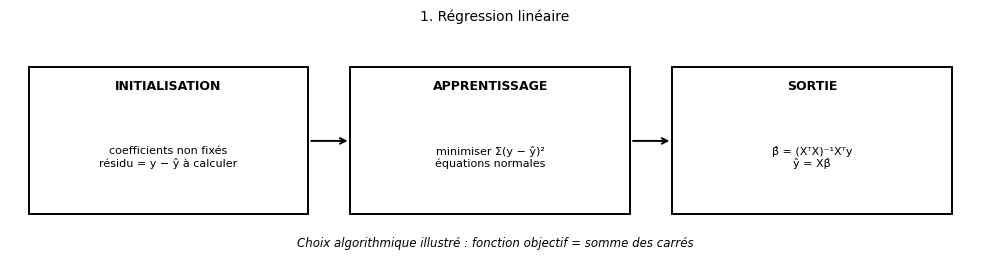

In [5]:
schema('1. Régression linéaire', ['coefficients non fixés\nrésidu = y − ŷ à calculer', 'minimiser Σ(y − ŷ)²\néquations normales', 'β̂ = (XᵀX)⁻¹Xᵀy\nŷ = Xβ̂'], 'fonction objectif = somme des carrés')

### Contextes et choix (C3)
- **Contextes :** (i) prévoir le chiffre d'affaires d'un point de vente à partir de sa surface, de son trafic et de la saison (commerce) ; (ii) estimer le coût de transport d'un conteneur selon la distance et le poids (logistique).
- **Structure attendue :** tableau numérique, une ligne par individu, peu de colonnes très corrélées, cible continue.
- **Concurrent :** Ridge ou forêt aléatoire. **Mal adapté :** relation fortement non linéaire ou variables quasi colinéaires (coefficients instables).
- **Métrique :** MAE si l'on veut une erreur lisible dans l'unité de la cible ; RMSE si les grosses erreurs coûtent cher ; R² pour comparer à la moyenne seule.

R² entraînement : 0.519 | R² test : 0.485
Résidus (test) — moyenne : 1.86 | écart-type : 53.34
Corrélation |résidu| / prédiction : 0.286
fit_intercept = True | MAE de validation croisée : 45.81
fit_intercept = False | MAE de validation croisée : 157.28


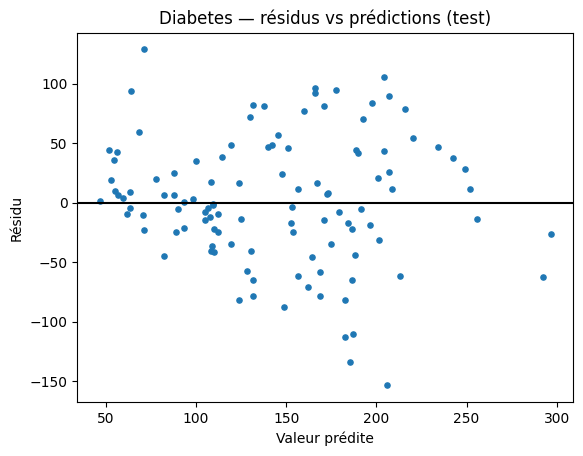

In [6]:
# C4 — hyperparamètre : fit_intercept ; diagnostic : résidus
modele = LinearRegression().fit(Xr_ent, yr_ent); predictions = modele.predict(Xr_test)
res = yr_test - predictions
print('R² entraînement :', round(modele.score(Xr_ent, yr_ent), 3), '| R² test :', round(r2_score(yr_test, predictions), 3))
print('Résidus (test) — moyenne :', round(res.mean(), 2), '| écart-type :', round(res.std(), 2))
print('Corrélation |résidu| / prédiction :', round(np.corrcoef(np.abs(res), predictions)[0, 1], 3))
for fi in [True, False]:
    print('fit_intercept =', fi, '| MAE de validation croisée :', cv_mae(LinearRegression(fit_intercept=fi), Xr_ent, yr_ent))
plt.scatter(predictions, res, s=14); plt.axhline(0, color='k')
plt.xlabel('Valeur prédite'); plt.ylabel('Résidu'); plt.title('Diabetes — résidus vs prédictions (test)'); plt.show()

### Test de sensibilité et interprétation (C4)
- **Résultat :** R² de 0,519 à l'entraînement et de 0,485 au test ; moyenne des résidus de test 1,86 pour un écart-type de 53,34. La corrélation entre |résidu| et prédiction est de 0,286.
- **Réponse à la question :** une mauvaise spécification linéaire se lit sur le graphique résidus contre prédictions : courbure (la relation n'est pas une droite) ou entonnoir (variance non constante). Ici la corrélation positive de 0,286 suggère des résidus plus étalés quand la prédiction est grande ; **regardez la figure** pour confirmer, ce chiffre seul ne le prouve pas.
- **Hyperparamètre modifié :** `fit_intercept=False` fait passer la MAE de validation croisée de 45,81 à 157,28. La cible a une moyenne élevée et les variables sont centrées : sans constante, le modèle ne peut plus reproduire cette moyenne.
- **Ce qu'on ne peut pas conclure :** une seule séparation entraînement/test (111 patients) ne dit pas si l'écart entre 0,519 et 0,485 est un vrai surajustement ou du hasard d'échantillonnage ; la MAE de validation (45,81) et la MAE de test (41,55) n'ont pas le même niveau, preuve que le jeu de test est plus « facile » ou simplement différent.

## 2. Ridge

**Variante C — question spécifique :** Comment évoluent les coefficients quand alpha augmente ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [7]:
from sklearn.linear_model import Ridge
modele = make_pipeline(StandardScaler(), Ridge(alpha=12.0)).fit(Xr_ent, yr_ent)
print('MAE Ridge :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

MAE Ridge : 41.46


### Présentation (C1)
- **Catégorie :** apprentissage supervisé, régression régularisée (pénalité L2).
- **Entrées / sortie :** variables numériques **standardisées** (la pénalité dépend de l'échelle) ; cible continue.
- **Hypothèse clé :** relation linéaire, mais avec des coefficients que l'on préfère petits pour stabiliser l'estimation quand les variables sont corrélées.
- **Étapes :** (1) centrer-réduire les variables sur l'entraînement ; (2) minimiser l'erreur quadratique **plus** une pénalité sur la taille des coefficients ; (3) solution fermée $\hat\beta=(X^\top X+\alpha I)^{-1}X^\top y$ ; (4) prédire.
- **Équation :** $\hat\beta=\arg\min_\beta\ \|y-X\beta\|_2^2+\alpha\|\beta\|_2^2$.
- **Symboles :** $\|\cdot\|_2$ norme euclidienne ; $\beta$ vecteur des coefficients ; $\alpha\ge 0$ force de la pénalité ; $I$ matrice identité.
- **Paramètres appris :** les coefficients $\beta$. **Hyperparamètre :** $\alpha$ (`alpha`), fixé avant l'apprentissage et choisi sur validation, jamais sur le test.
- **Effet :** quand $\alpha$ augmente, les coefficients rétrécissent vers 0 sans être annulés.

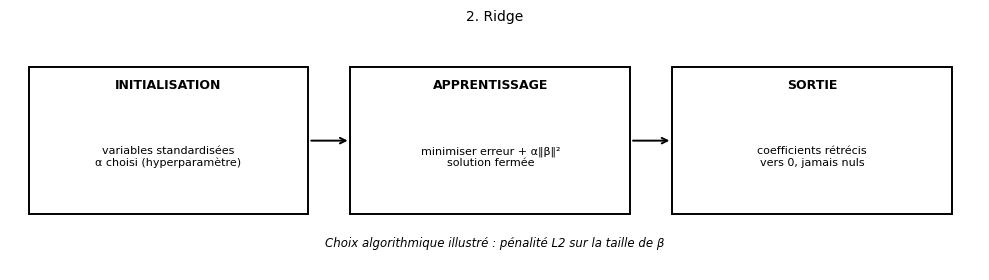

In [8]:
schema('2. Ridge', ['variables standardisées\nα choisi (hyperparamètre)', 'minimiser erreur + α‖β‖²\nsolution fermée', 'coefficients rétrécis\nvers 0, jamais nuls'], 'pénalité L2 sur la taille de β')

### Contextes et choix (C3)
- **Contextes :** (i) scoring de la valeur d'un panier client à partir de dizaines de variables d'historique d'achat corrélées (marketing) ; (ii) prévision de la demande d'un produit avec plusieurs indicateurs macroéconomiques proches (gestion).
- **Structure attendue :** tableau numérique avec beaucoup de colonnes corrélées, peu d'observations par rapport au nombre de variables.
- **Concurrent :** Lasso (sélection de variables) ou régression linéaire simple. **Mal adapté :** quand on veut éliminer des variables inutiles (Ridge les garde toutes), ou quand les variables n'ont pas été standardisées.
- **Métrique :** MAE ou RMSE sur un jeu de validation ; la norme des coefficients sert de diagnostic de régularisation, pas de score.

In [9]:
# C4 — hyperparamètre : alpha (MAE de validation croisée sur l'entraînement)
for a in [0.01, 1, 12, 100, 1000]:
    p = make_pipeline(StandardScaler(), Ridge(alpha=a))
    coef = p.fit(Xr_ent, yr_ent)[-1].coef_
    print('alpha =', a, '| MAE validation :', cv_mae(p, Xr_ent, yr_ent), '| norme des coefficients :', round(float(np.linalg.norm(coef)), 2))

alpha = 0.01 | MAE validation : 45.81 | norme des coefficients : 70.31
alpha = 1 | MAE validation : 45.75 | norme des coefficients : 59.75
alpha = 12 | MAE validation : 45.91 | norme des coefficients : 41.99
alpha = 100 | MAE validation : 47.19 | norme des coefficients : 33.79
alpha = 1000 | MAE validation : 56.01 | norme des coefficients : 15.16


### Test de sensibilité et interprétation (C4)
- **Résultat (MAE de validation croisée) :** 45,81 pour $\alpha=0{,}01$, 45,75 pour 1, 45,91 pour 12, 47,19 pour 100 et 56,01 pour 1000. La norme des coefficients tombe de 70,31 à 15,16.
- **Réponse à la question :** quand $\alpha$ augmente, les coefficients rétrécissent de façon continue, sans s'annuler.
- **Explication :** la pénalité $\alpha\|\beta\|^2$ force un compromis ; un $\alpha$ modéré (1 à 12) laisse l'erreur presque inchangée mais stabilise les coefficients ; un $\alpha$ trop grand sous-ajuste.
- **Ce qu'on ne peut pas conclure :** les écarts entre 0,01, 1 et 12 (0,16 point de MAE au plus) sont trop faibles pour désigner un meilleur $\alpha$ avec 331 observations ; seul 1000 est nettement moins bon. Le réglage 12 du code d'origine n'est donc ni prouvé optimal ni mauvais.

## 3. Lasso

**Variante C — question spécifique :** Combien de variables sont annulées pour trois valeurs d’alpha ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [10]:
from sklearn.linear_model import Lasso
modele = make_pipeline(StandardScaler(), Lasso(alpha=2.0, max_iter=15000)).fit(Xr_ent, yr_ent)
print('Nombre de coefficients non nuls :', np.count_nonzero(modele[-1].coef_))
print('MAE Lasso :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

Nombre de coefficients non nuls : 8
MAE Lasso : 41.37


### Présentation (C1)
- **Catégorie :** apprentissage supervisé, régression régularisée (pénalité L1) avec sélection de variables.
- **Entrées / sortie :** variables numériques standardisées ; cible continue.
- **Hypothèse clé :** peu de variables portent l'essentiel du signal (modèle « parcimonieux »).
- **Étapes :** (1) standardiser ; (2) minimiser l'erreur quadratique plus la somme des valeurs absolues des coefficients ; (3) résolution itérative (descente de coordonnées, `max_iter`) ; (4) certains coefficients tombent exactement à 0.
- **Équation :** $\hat\beta=\arg\min_\beta\ \frac{1}{2n}\|y-X\beta\|_2^2+\alpha\|\beta\|_1$.
- **Symboles :** $n$ nombre d'observations ; $\|\beta\|_1=\sum_j|\beta_j|$ ; $\alpha\ge0$ force de la pénalité (convention de scikit-learn : le terme d'erreur est divisé par $2n$).
- **Paramètres appris :** les coefficients $\beta_j$ (dont certains nuls). **Hyperparamètres :** `alpha`, `max_iter` (critère d'arrêt de l'algorithme, sans effet sur le modèle s'il converge).
- **Question posée :** combien de coefficients restent non nuls pour trois valeurs de $\alpha$ ?

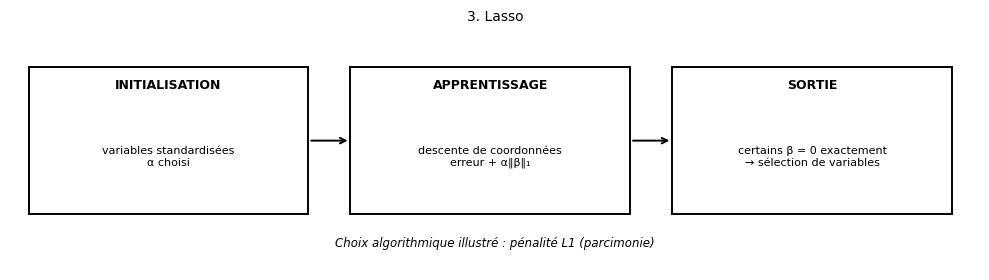

In [11]:
schema('3. Lasso', ['variables standardisées\nα choisi', 'descente de coordonnées\nerreur + α‖β‖₁', 'certains β = 0 exactement\n→ sélection de variables'], 'pénalité L1 (parcimonie)')

### Contextes et choix (C3)
- **Contextes :** (i) repérer les quelques indicateurs financiers qui expliquent la note de crédit d'une PME parmi des dizaines de ratios (finance) ; (ii) identifier les leviers de coût qui comptent dans une chaîne logistique.
- **Structure attendue :** beaucoup de variables candidates, dont plusieurs inutiles ; variables standardisées.
- **Concurrent :** Ridge (qui conserve tout) ou Elastic Net. **Mal adapté :** variables très corrélées entre elles : Lasso en garde une, presque au hasard, et le choix peut changer d'un échantillon à l'autre.
- **Métrique :** MAE de validation et nombre de coefficients non nuls (lisibilité du modèle).

In [12]:
# C4 — hyperparamètre : alpha
for a in [0.1, 2.0, 10.0]:
    p = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=15000))
    coef = p.fit(Xr_ent, yr_ent)[-1].coef_
    print('alpha =', a, '| coefficients non nuls :', np.count_nonzero(coef), '/', len(coef), '| MAE validation :', cv_mae(p, Xr_ent, yr_ent))

alpha = 0.1 | coefficients non nuls : 9 / 10 | MAE validation : 45.75
alpha = 2.0 | coefficients non nuls : 8 / 10 | MAE validation : 46.54
alpha = 10.0 | coefficients non nuls : 4 / 10 | MAE validation : 49.67


### Test de sensibilité et interprétation (C4)
- **Résultat :** 9 coefficients non nuls sur 10 pour $\alpha=0{,}1$ (MAE de validation 45,75), 8 pour $\alpha=2$ (46,54) et 4 pour $\alpha=10$ (49,67).
- **Réponse à la question :** le nombre de variables conservées baisse quand $\alpha$ augmente, ce qui est la sélection de variables propre à la pénalité L1.
- **Explication :** la pénalité L1 a un « coin » en 0 : les coefficients peu utiles sont ramenés exactement à 0, au prix d'un biais (MAE de validation qui monte de 45,75 à 49,67).
- **Ce qu'on ne peut pas conclure :** les variables retirées ne sont pas « sans effet » : elles sont retirées pour cet échantillon et cet $\alpha$ ; avec des variables corrélées, un autre échantillon pourrait en retenir d'autres. Il faudrait répéter sur plusieurs rééchantillonnages pour juger de la stabilité de la sélection.

## 4. Régression polynomiale

**Variante C — question spécifique :** Le degré 2 améliore-t-il le test ou seulement l’entraînement ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [13]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
modele = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2, include_bias=False), Ridge(alpha=100.)).fit(Xr_ent, yr_ent)
print('R² polynomial :', round(r2_score(yr_test, modele.predict(Xr_test)), 3))

R² polynomial : 0.501


### Présentation (C1)
- **Catégorie :** apprentissage supervisé, régression (extension non linéaire d'un modèle linéaire).
- **Entrées / sortie :** variables numériques ; cible continue. Les variables sont enrichies de leurs puissances et produits croisés.
- **Hypothèse clé :** la relation est lisse et peut s'écrire comme un polynôme de faible degré des variables.
- **Étapes :** (1) standardiser ; (2) générer les termes $x_j$, $x_j^2$, $x_jx_k$ jusqu'au degré $d$ ; (3) ajuster un modèle linéaire pénalisé (ici Ridge) sur ces nouvelles colonnes ; (4) prédire.
- **Équation (degré 2) :** $\hat y=\beta_0+\sum_j\beta_jx_j+\sum_{j\le k}\beta_{jk}x_jx_k$.
- **Symboles :** $x_j$ variable $j$ ; $\beta_j,\beta_{jk}$ coefficients des termes simples et croisés ; $d$ degré maximal.
- **Paramètres appris :** les coefficients $\beta$. **Hyperparamètres :** le degré $d$ et la pénalité `alpha` du Ridge.
- **Risque :** pour $p=10$ variables, le degré 2 crée 65 colonnes ($p+p(p+1)/2$, hors constante) ; le degré 3 en crée 285 : le surajustement monte vite.

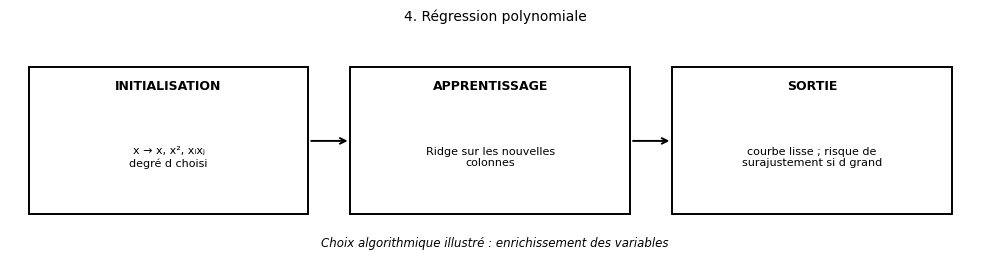

In [14]:
schema('4. Régression polynomiale', ['x → x, x², xᵢxⱼ\ndegré d choisi', 'Ridge sur les nouvelles\ncolonnes', 'courbe lisse ; risque de\nsurajustement si d grand'], 'enrichissement des variables')

### Contextes et choix (C3)
- **Contextes :** (i) courbe de réponse des ventes à un budget publicitaire avec rendements décroissants (marketing) ; (ii) relation entre vitesse de navigation et consommation de carburant d'un navire (logistique).
- **Structure attendue :** peu de variables explicatives, relation courbe visible sur un graphique.
- **Concurrent :** forêt aléatoire ou boosting. **Mal adapté :** beaucoup de variables et peu d'observations (explosion du nombre de termes), ou extrapolation hors du domaine observé (le polynôme diverge).
- **Métrique :** comparer R² **entraînement et test** : le seul R² d'entraînement augmente toujours avec le degré et ne prouve rien.

In [15]:
# C4 — hyperparamètre : degré (R² entraînement vs validation)
for d in [1, 2, 3]:
    p = make_pipeline(StandardScaler(), PolynomialFeatures(d, include_bias=False), Ridge(alpha=100.))
    tr, va = cv_train_val(p, Xr_ent, yr_ent, 'r2', CV_REG)
    print('degré =', d, '| colonnes :', p.fit(Xr_ent, yr_ent)[1].n_output_features_, '| R² entraînement :', tr, '| R² validation :', va)

degré = 1 | colonnes : 10 | R² entraînement : 0.5 | R² validation : 0.448
degré = 2 | colonnes : 65 | R² entraînement : 0.563 | R² validation : 0.416
degré = 3 | colonnes : 285 | R² entraînement : 0.686 | R² validation : 0.222


### Test de sensibilité et interprétation (C4)
- **Résultat :** degré 1 : R² d'entraînement 0,5 et de validation 0,448 ; degré 2 : 0,563 et 0,416 ; degré 3 : 0,686 et 0,222. Les colonnes passent de 10 à 65 puis 285.
- **Réponse à la question :** le degré 2 améliore l'entraînement ; la validation, elle, baisse (0,448 → 0,416), et s'effondre au degré 3. Le R² de test du code d'origine (0,501 pour le degré 2, contre 0,485 pour la régression linéaire de la section 1) est légèrement plus haut, mais la validation croisée ne confirme pas ce gain.
- **Explication :** plus de termes donnent plus de souplesse ; avec 331 observations, la souplesse supplémentaire est du bruit ajusté.
- **Ce qu'on ne peut pas conclure :** deux mesures indépendantes (test et validation) ne vont pas dans le même sens pour le degré 2 : l'écart est dans le bruit d'échantillonnage. On ne peut donc affirmer ni que le degré 2 aide, ni qu'il nuit.

## 5. Arbre de régression

**Variante C — question spécifique :** Quel effet de max_depth sur le biais et la variance ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [16]:
from sklearn.tree import DecisionTreeRegressor
modele = DecisionTreeRegressor(max_depth=3, min_samples_leaf=8, random_state=GRAINE).fit(Xr_ent, yr_ent)
print('MAE arbre :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

MAE arbre : 44.57


### Présentation (C1)
- **Catégorie :** apprentissage supervisé, régression par arbre.
- **Entrées / sortie :** variables numériques ou ordinales ; cible continue.
- **Hypothèse clé :** l'espace peut être découpé en régions où la cible est à peu près constante.
- **Étapes :** (1) tester tous les seuils de toutes les variables ; (2) garder la coupure qui réduit le plus l'erreur quadratique ; (3) répéter sur chaque sous-groupe jusqu'à `max_depth` ou `min_samples_leaf` ; (4) la prédiction d'une feuille est la moyenne de ses observations.
- **Équation :** $\hat y(x)=\frac{1}{|F|}\sum_{i\in F(x)}y_i$, avec la coupure choisie par $\min_{j,s}\big[\sum_{i\in G}(y_i-\bar y_G)^2+\sum_{i\in D}(y_i-\bar y_D)^2\big]$.
- **Symboles :** $F(x)$ feuille où tombe $x$ ; $|F|$ son effectif ; $j$ variable, $s$ seuil ; $G$ et $D$ sous-groupes gauche et droit ; $\bar y_G,\bar y_D$ leurs moyennes.
- **Paramètres appris :** variables et seuils de coupure, valeurs des feuilles. **Hyperparamètres :** `max_depth`, `min_samples_leaf`.
- **Question posée :** effet de `max_depth` sur le biais (modèle trop simple) et la variance (modèle instable).

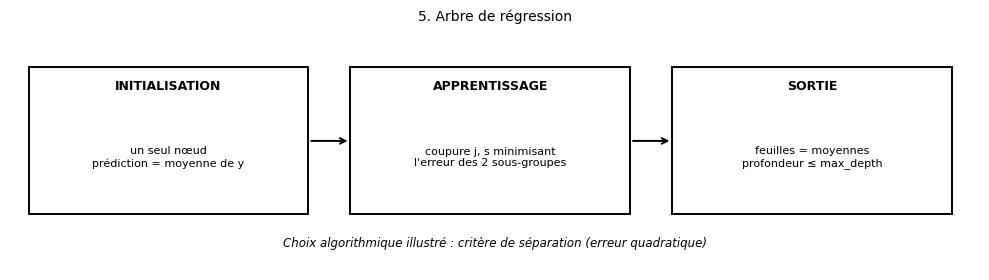

In [17]:
schema('5. Arbre de régression', ['un seul nœud\nprédiction = moyenne de y', "coupure j, s minimisant\nl'erreur des 2 sous-groupes", 'feuilles = moyennes\nprofondeur ≤ max_depth'], 'critère de séparation (erreur quadratique)')

### Contextes et choix (C3)
- **Contextes :** (i) estimer le prix de vente de véhicules d'occasion avec des règles lisibles (commerce) ; (ii) fixer un délai de livraison par palier selon le poids et la destination (logistique).
- **Structure attendue :** données hétérogènes (numériques et catégorielles codées), interactions entre variables.
- **Concurrent :** forêt aléatoire. **Mal adapté :** relation lisse et linéaire (l'arbre la découpe en marches d'escalier) ; un arbre profond est aussi instable : un léger changement des données modifie sa forme.
- **Métrique :** MAE entraînement **et** test selon la profondeur ; l'écart entre les deux mesure la variance.

In [18]:
# C4 — hyperparamètre : max_depth (MAE entraînement vs validation)
for d in [1, 2, 3, 5, 8, None]:
    p = DecisionTreeRegressor(max_depth=d, min_samples_leaf=8, random_state=GRAINE)
    tr, va = cv_train_val(p, Xr_ent, yr_ent, 'neg_mean_absolute_error', CV_REG)
    print('max_depth =', d, '| MAE entraînement :', tr, '| MAE validation :', va)

max_depth = 1 | MAE entraînement : 54.316 | MAE validation : 58.499
max_depth = 2 | MAE entraînement : 47.069 | MAE validation : 53.857
max_depth = 3 | MAE entraînement : 42.643 | MAE validation : 55.442
max_depth = 5 | MAE entraînement : 37.007 | MAE validation : 57.565
max_depth = 8 | MAE entraînement : 33.878 | MAE validation : 58.046
max_depth = None | MAE entraînement : 33.653 | MAE validation : 57.89


### Test de sensibilité et interprétation (C4)
- **Résultat (MAE) :** profondeur 1 : entraînement 54,316 / validation 58,499 ; profondeur 2 : 47,069 / 53,857 ; profondeur 3 : 42,643 / 55,442 ; profondeur 5 : 37,007 / 57,565 ; profondeur 8 : 33,878 / 58,046 ; sans limite : 33,653 / 57,89.
- **Réponse à la question :** l'erreur d'entraînement baisse toujours avec la profondeur (biais décroissant) ; l'erreur de validation est minimale à la profondeur 2 puis remonte (variance croissante, arbre qui mémorise).
- **Explication :** un arbre profond a des feuilles de quelques individus, dont la moyenne est très instable.
- **Ce qu'on ne peut pas conclure :** l'optimum « profondeur 2 » vient d'une validation croisée à 5 plis ; l'écart avec la profondeur 3 (1,6 point) est modeste. La MAE de test du code d'origine (profondeur 3 : 44,57) est plus basse que celle de validation (55,44) : on ne compare pas ces deux niveaux.

## 6. Forêt aléatoire — régression

**Variante C — question spécifique :** La forêt réduit-elle la variance par rapport à l’arbre ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [19]:
from sklearn.ensemble import RandomForestRegressor
modele = RandomForestRegressor(n_estimators=60, max_depth=6, n_jobs=-1, random_state=GRAINE).fit(Xr_ent, yr_ent)
print('MAE forêt :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

MAE forêt : 43.11


### Présentation (C1)
- **Catégorie :** apprentissage supervisé, régression par ensemble (bagging d'arbres).
- **Entrées / sortie :** variables numériques ; cible continue.
- **Hypothèse clé :** des arbres entraînés sur des échantillons différents font des erreurs en partie indépendantes ; leur moyenne est plus stable.
- **Étapes :** (1) tirer $B$ échantillons bootstrap (avec remise) ; (2) entraîner un arbre sur chacun, avec un sous-ensemble aléatoire de variables à chaque coupure ; (3) moyenner les prédictions.
- **Équation :** $\hat y(x)=\frac1B\sum_{b=1}^{B}T_b(x)$.
- **Symboles :** $B$ nombre d'arbres (`n_estimators`) ; $T_b$ le $b$-ième arbre ; $x$ une observation.
- **Paramètres appris :** les coupures et valeurs de feuille de chaque arbre. **Hyperparamètres :** `n_estimators`, `max_depth`, `max_features`.
- **Question posée :** la forêt réduit-elle la variance par rapport à un arbre seul ? On le mesure en changeant la graine aléatoire plusieurs fois.

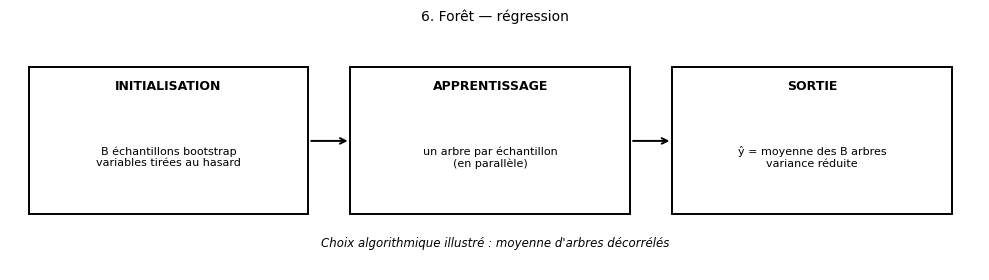

In [20]:
schema('6. Forêt — régression', ['B échantillons bootstrap\nvariables tirées au hasard', 'un arbre par échantillon\n(en parallèle)', 'ŷ = moyenne des B arbres\nvariance réduite'], "moyenne d'arbres décorrélés")

### Contextes et choix (C3)
- **Contextes :** (i) prévision de la demande par référence et par magasin, avec des effets non linéaires (commerce) ; (ii) estimation du délai de dédouanement selon le type de marchandise, le pays et la période (commerce international).
- **Structure attendue :** tableau mixte, interactions, valeurs aberrantes possibles.
- **Concurrent :** boosting. **Mal adapté :** extrapolation hors des valeurs vues (une forêt ne prédit jamais au-delà des cibles d'entraînement) ; besoin d'un modèle explicable ligne par ligne.
- **Métrique :** MAE dans l'unité de la cible, et écart-type de la MAE sur plusieurs graines pour mesurer la stabilité.

In [21]:
# C4 — n_estimators, puis variabilité selon la graine (arbre seul vs forêt)
for n in [1, 10, 60, 200]:
    p = RandomForestRegressor(n_estimators=n, max_depth=6, n_jobs=-1, random_state=GRAINE)
    print('n_estimators =', n, '| MAE validation :', cv_mae(p, Xr_ent, yr_ent))
for nom, fabrique in [('arbre', lambda s: DecisionTreeRegressor(max_depth=6, min_samples_leaf=8, random_state=s)),
                      ('forêt', lambda s: RandomForestRegressor(n_estimators=60, max_depth=6, n_jobs=-1, random_state=s))]:
    v = [cv_mae(fabrique(s), Xr_ent, yr_ent) for s in range(5)]
    print(nom, '— MAE validation sur 5 graines : moyenne', round(np.mean(v), 2), '| écart-type', round(np.std(v), 3))

n_estimators = 1 | MAE validation : 64.34
n_estimators = 10 | MAE validation : 50.93
n_estimators = 60 | MAE validation : 50.22
n_estimators = 200 | MAE validation : 49.81
arbre — MAE validation sur 5 graines : moyenne 57.63 | écart-type 0.0
forêt — MAE validation sur 5 graines : moyenne 49.92 | écart-type 0.208


### Test de sensibilité et interprétation (C4)
- **Résultat :** MAE de validation 64,34 avec 1 arbre, 50,93 avec 10, 50,22 avec 60 et 49,81 avec 200. Sur 5 graines, l'arbre seul (profondeur 6) donne 57,63 (écart-type 0) et la forêt 49,92 (écart-type 0,208).
- **Réponse à la question :** la forêt a une erreur de validation plus basse que l'arbre (49,92 contre 57,63), ce qui est cohérent avec une réduction de variance par moyennage.
- **Explication :** les arbres entraînés sur des échantillons bootstrap font des erreurs en partie indépendantes ; leur moyenne atténue les fluctuations. Au-delà de 10 arbres, le gain est faible (50,93 → 49,81).
- **Ce qu'on ne peut pas conclure :** l'écart-type entre graines (0 pour l'arbre, qui est déterministe ici) mesure la variabilité due au tirage aléatoire, **pas** la variance due au choix de l'échantillon d'entraînement. Pour cette dernière, il faudrait rééchantillonner les données.

## 7. Gradient Boosting — régression

**Variante C — question spécifique :** Que change max_iter sur le coût et le risque de surajustement ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [22]:
from sklearn.ensemble import HistGradientBoostingRegressor
modele = HistGradientBoostingRegressor(max_iter=100, max_leaf_nodes=9, random_state=GRAINE).fit(Xr_ent, yr_ent)
print('MAE boosting :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

MAE boosting : 44.18


### Présentation (C1)
- **Catégorie :** apprentissage supervisé, régression par boosting d'arbres.
- **Entrées / sortie :** variables numériques ; cible continue.
- **Hypothèse clé :** on peut corriger progressivement les erreurs d'un modèle en lui ajoutant de petits arbres.
- **Étapes :** (1) partir d'une prédiction constante (la moyenne) ; (2) calculer les résidus ; (3) ajuster un petit arbre sur ces résidus ; (4) l'ajouter au modèle, pondéré par le pas d'apprentissage ; (5) répéter `max_iter` fois.
- **Équation :** $F_m(x)=F_{m-1}(x)+\eta\,h_m(x)$, où $h_m$ est ajusté sur $r_i=y_i-F_{m-1}(x_i)$.
- **Symboles :** $F_m$ modèle après $m$ arbres ; $\eta$ pas d'apprentissage (`learning_rate`) ; $h_m$ $m$-ième arbre ; $r_i$ résidu de l'individu $i$.
- **Paramètres appris :** les arbres $h_m$ (coupures et feuilles). **Hyperparamètres :** `max_iter`, `max_leaf_nodes`, `learning_rate`.
- **Question posée :** que change `max_iter` sur le coût de calcul et le risque de surajustement ? On désactive l'arrêt précoce pour isoler l'effet.

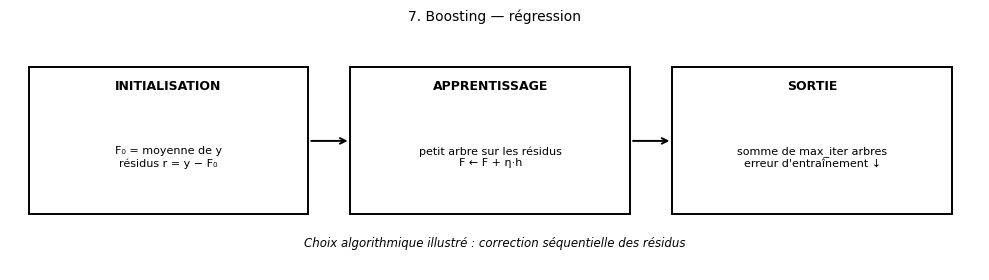

In [23]:
schema('7. Boosting — régression', ['F₀ = moyenne de y\nrésidus r = y − F₀', 'petit arbre sur les résidus\nF ← F + η·h', "somme de max_iter arbres\nerreur d'entraînement ↓"], 'correction séquentielle des résidus')

### Contextes et choix (C3)
- **Contextes :** (i) modèle de prévision des ventes sur des données de caisse volumineuses (commerce) ; (ii) estimation du risque de retard d'une expédition (logistique).
- **Structure attendue :** tableau de taille moyenne à grande, relations non linéaires et interactions.
- **Concurrent :** forêt aléatoire. **Mal adapté :** très peu de données ou cible très bruitée : le boosting ajuste le bruit si `max_iter` est trop grand.
- **Métrique :** MAE sur un jeu de validation ; surveiller l'écart entre MAE d'entraînement et de test.

In [24]:
# C4 — hyperparamètre : max_iter (arrêt précoce désactivé pour isoler l'effet)
for it in [10, 100, 400]:
    p = HistGradientBoostingRegressor(max_iter=it, max_leaf_nodes=9, early_stopping=False, random_state=GRAINE)
    t0 = time.time(); tr, va = cv_train_val(p, Xr_ent, yr_ent, 'neg_mean_absolute_error', CV_REG)
    print('max_iter =', it, '| MAE entraînement :', tr, '| MAE validation :', va, '| temps (5 plis) :', round(time.time() - t0, 2), 's')

max_iter = 10 | MAE entraînement : 45.565 | MAE validation : 53.341 | temps (5 plis) : 0.12 s
max_iter = 100 | MAE entraînement : 19.078 | MAE validation : 50.408 | temps (5 plis) : 0.58 s
max_iter = 400 | MAE entraînement : 4.472 | MAE validation : 52.557 | temps (5 plis) : 1.68 s


### Test de sensibilité et interprétation (C4)
- **Résultat :** `max_iter`=10 : MAE d'entraînement 45,565 et de validation 53,341 (0,11 s) ; 100 : 19,078 et 50,408 (0,33 s) ; 400 : 4,472 et 52,557 (1,15 s).
- **Réponse à la question :** le temps croît à peu près proportionnellement au nombre d'arbres, et l'erreur d'entraînement s'effondre (de 45,6 à 4,5), alors que celle de validation passe par un minimum vers 100 puis remonte : signe de surajustement.
- **Explication :** chaque arbre supplémentaire corrige un peu plus les résidus d'entraînement, y compris le bruit.
- **Ce qu'on ne peut pas conclure :** la valeur « 100 » n'est pas un optimum démontré (trois valeurs seulement testées, `learning_rate` fixe) ; les temps dépendent de la machine et de la charge, ils n'indiquent qu'un ordre de grandeur.

## 8. Régression logistique

**Variante C — question spécifique :** Quel effet de C sur les probabilités et la frontière ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [25]:
from sklearn.linear_model import LogisticRegression
modele = make_pipeline(StandardScaler(), LogisticRegression(C=.5, max_iter=2000, random_state=GRAINE)).fit(Xc_ent, yc_ent)
print('F1 logistique :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 logistique : 0.989


### Présentation (C1)
- **Catégorie :** apprentissage supervisé, classification binaire (tumeur bénigne ou maligne).
- **Entrées / sortie :** 30 variables numériques standardisées ; étiquette 0/1 et probabilité $P(y=1\mid x)$.
- **Hypothèse clé :** le logarithme du rapport de chances est une fonction linéaire des variables.
- **Étapes :** (1) calculer le score linéaire $z=\beta_0+\beta^\top x$ ; (2) le transformer en probabilité par la fonction logistique ; (3) minimiser l'entropie croisée pénalisée ; (4) classer selon le seuil de 0,5.
- **Équation :** $P(y=1\mid x)=\sigma(z)=\dfrac{1}{1+e^{-z}}$, $z=\beta_0+\beta^\top x$.
- **Symboles :** $\sigma$ fonction logistique ; $z$ score ; $\beta_0,\beta$ coefficients ; $x$ vecteur des variables.
- **Paramètres appris :** $\beta_0,\beta$. **Hyperparamètre :** $C$, l'**inverse** de la force de la pénalité L2 (petit $C$ = forte pénalité).
- **Question posée :** effet de $C$ sur les probabilités et la frontière de décision.

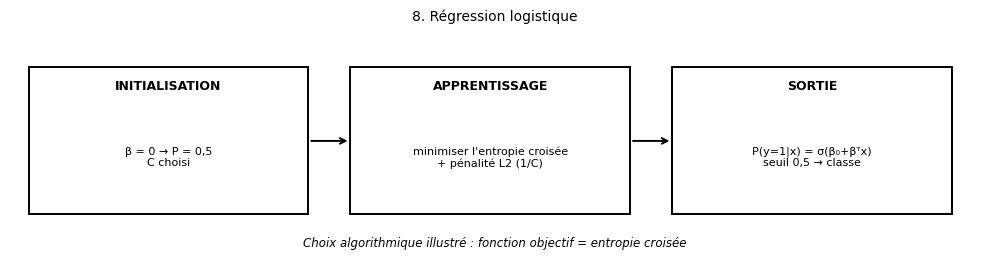

In [26]:
schema('8. Régression logistique', ['β = 0 → P = 0,5\nC choisi', "minimiser l'entropie croisée\n+ pénalité L2 (1/C)", 'P(y=1|x) = σ(β₀+βᵀx)\nseuil 0,5 → classe'], 'fonction objectif = entropie croisée')

### Contextes et choix (C3)
- **Contextes :** (i) probabilité de défaut de paiement d'un client à partir de son historique (finance) ; (ii) probabilité qu'un prospect réponde à une campagne d'e-mailing (marketing).
- **Structure attendue :** variables numériques standardisées (ou encodées), cible binaire, classes pas trop déséquilibrées.
- **Concurrent :** forêt ou boosting. **Mal adapté :** frontière très non linéaire sans variables d'interaction ; classes parfaitement séparables (coefficients qui divergent sans pénalité).
- **Métrique :** ROC-AUC si l'on classe des profils par risque ; F1 si l'on doit choisir un seuil ; en finance, regarder aussi le coût d'un faux négatif.

In [27]:
# C4 — hyperparamètre : C (inverse de la pénalité)
for C in [0.01, 0.5, 100]:
    p = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000, random_state=GRAINE))
    p.fit(Xc_ent, yc_ent); proba = p.predict_proba(Xc_ent)[:, 1]
    print('C =', C, '| F1 validation :', cv_f1(p, Xc_ent, yc_ent),
          '| norme des coefficients :', round(float(np.linalg.norm(p[-1].coef_)), 2),
          '| part de probabilités entre 0,05 et 0,95 (entraînement) :', round(float(np.mean((proba > .05) & (proba < .95))), 3))

C = 0.01 | F1 validation : 0.963 | norme des coefficients : 0.81 | part de probabilités entre 0,05 et 0,95 (entraînement) : 0.704
C = 0.5 | F1 validation : 0.982 | norme des coefficients : 2.87 | part de probabilités entre 0,05 et 0,95 (entraînement) : 0.176
C = 100 | F1 validation : 0.972 | norme des coefficients : 27.82 | part de probabilités entre 0,05 et 0,95 (entraînement) : 0.054


### Test de sensibilité et interprétation (C4)
- **Résultat :** $C=0{,}01$ : F1 de validation 0,963, norme des coefficients 0,81, 70,4 % de probabilités d'entraînement entre 0,05 et 0,95 ; $C=0{,}5$ : 0,982, 2,87, 17,6 % ; $C=100$ : 0,972, 27,82, 5,4 %.
- **Réponse à la question :** quand $C$ augmente (pénalité plus faible), les coefficients grandissent, les probabilités deviennent plus tranchées (proches de 0 ou 1) et la frontière épouse mieux l'entraînement.
- **Explication :** $C$ est l'inverse de la pénalité : petit $C$ = coefficients petits = modèle prudent mais peu confiant.
- **Ce qu'on ne peut pas conclure :** le meilleur F1 (0,982 à $C=0{,}5$) n'est pas prouvé meilleur que 0,972 : l'écart est de l'ordre de quelques observations sur 426. La part de probabilités « incertaines » est une mesure d'entraînement, **pas** une preuve de calibration.

## 9. KNN

**Variante C — question spécifique :** Comparez k = 3, 7 et 15 ; quelle métrique varie ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [28]:
from sklearn.neighbors import KNeighborsClassifier
modele = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7, weights='distance')).fit(Xc_ent, yc_ent)
print('F1 KNN :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 KNN : 0.984


### Présentation (C1)
- **Catégorie :** apprentissage supervisé, classification par plus proches voisins (méthode à base d'instances, sans phase d'ajustement de coefficients).
- **Entrées / sortie :** variables numériques **standardisées** (la distance dépend de l'échelle) ; classe prédite.
- **Hypothèse clé :** des observations proches dans l'espace des variables ont la même classe.
- **Étapes :** (1) mémoriser l'entraînement ; (2) pour un nouvel individu, calculer sa distance à tous les points ; (3) retenir les $k$ plus proches ; (4) voter, avec poids $1/d$ ici (`weights='distance'`).
- **Équation :** $\hat y(x)=\arg\max_c\sum_{i\in V_k(x)}w_i\,\mathbb{1}[y_i=c]$, $d(x,x_i)=\|x-x_i\|_2$, $w_i=1/d(x,x_i)$.
- **Symboles :** $V_k(x)$ ensemble des $k$ voisins ; $c$ une classe ; $w_i$ poids du voisin $i$ ; $\mathbb{1}[\cdot]$ indicatrice.
- **Paramètres appris :** aucun coefficient (le « modèle » est l'échantillon d'entraînement). **Hyperparamètres :** $k$, `weights`, la distance.
- **Question posée :** comparer $k=3,7,15$ ; quelle métrique varie ?

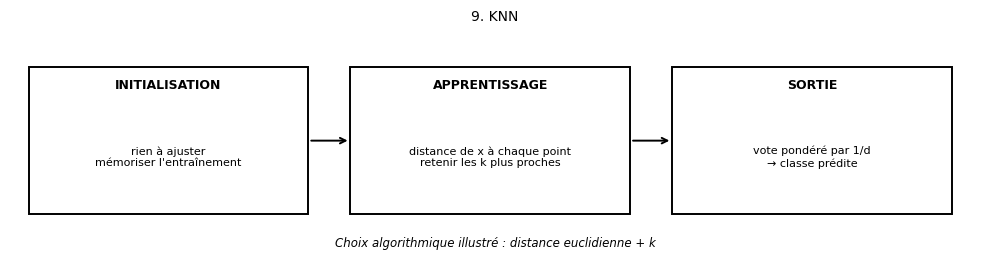

In [29]:
schema('9. KNN', ["rien à ajuster\nmémoriser l'entraînement", 'distance de x à chaque point\nretenir les k plus proches', 'vote pondéré par 1/d\n→ classe prédite'], 'distance euclidienne + k')

### Contextes et choix (C3)
- **Contextes :** (i) recommander des produits proches de ceux déjà achetés par des clients similaires (marketing) ; (ii) classer un colis dans une catégorie tarifaire à partir de dimensions et de poids (logistique).
- **Structure attendue :** peu de variables, toutes pertinentes et à la même échelle, volume modéré (prédiction lente sur de grandes bases).
- **Concurrent :** régression logistique ou SVM. **Mal adapté :** grande dimension avec beaucoup de variables inutiles (les distances deviennent peu informatives), ou variables non standardisées.
- **Métrique :** F1 et ROC-AUC ; la probabilité d'un KNN n'a que $k+1$ valeurs possibles, ce qui limite la finesse du classement.

In [ ]:
# C4 — hyperparamètre : k
for k in [3, 7, 15]:
    p = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k, weights='distance'))
    auc = round(cross_val_score(p, Xc_ent, yc_ent, cv=CV_CLS, scoring='roc_auc').mean(), 3)
    print('k =', k, '| F1 validation :', cv_f1(p, Xc_ent, yc_ent), '| ROC-AUC validation :', auc)

### Test de sensibilité et interprétation (C4)
- **Résultat (validation croisée) :** $k=3$ : F1 0,971, ROC-AUC 0,973 ; $k=7$ : 0,973 et 0,989 ; $k=15$ : 0,976 et 0,988.
- **Réponse à la question :** c'est surtout le ROC-AUC qui varie entre $k=3$ et $k\ge7$ (0,973 contre 0,989) ; le F1 bouge à peine (0,971 à 0,976).
- **Explication (hypothèse plausible, non testée ici) :** avec $k=3$, la probabilité est estimée sur très peu de voisins, donc le classement des individus est plus instable, d'où un AUC plus bas ; un $k$ plus grand lisse la décision.
- **Ce qu'on ne peut pas conclure :** les écarts de F1 (≤ 0,005) sont dans le bruit ; on ne peut pas dire que $k=15$ est « meilleur » en F1. Le F1 de test du code d'origine ($k=7$, 0,984) vient d'un autre échantillon que la validation.

## 10. Naive Bayes

**Variante C — question spécifique :** Dans quel cas l’hypothèse d’indépendance devient-elle critique ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.naive_bayes import GaussianNB
modele = GaussianNB(var_smoothing=1e-8).fit(Xc_ent, yc_ent)
print('F1 Naive Bayes :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

### Présentation (C1)
- **Catégorie :** apprentissage supervisé, classification probabiliste (modèle génératif).
- **Entrées / sortie :** variables numériques ; classe prédite et probabilités a posteriori.
- **Hypothèse clé :** **indépendance conditionnelle** des variables sachant la classe, avec une loi gaussienne par variable et par classe.
- **Étapes :** (1) estimer la moyenne et la variance de chaque variable dans chaque classe ; (2) estimer les probabilités a priori ; (3) pour un nouvel individu, multiplier les vraisemblances ; (4) choisir la classe de plus grande probabilité.
- **Équation :** $\hat y=\arg\max_c\ P(c)\prod_{j=1}^{p}\mathcal N(x_j\mid\mu_{cj},\sigma_{cj}^2)$.
- **Symboles :** $P(c)$ probabilité a priori de la classe $c$ ; $\mu_{cj},\sigma^2_{cj}$ moyenne et variance de la variable $j$ dans la classe $c$ ; $\mathcal N$ densité gaussienne.
- **Paramètres appris :** $P(c),\mu_{cj},\sigma^2_{cj}$. **Hyperparamètre :** `var_smoothing` (fraction de la plus grande variance ajoutée aux variances pour la stabilité numérique).
- **Question posée :** dans quel cas l'indépendance devient-elle critique ? On mesure la corrélation entre variables.

In [ ]:
schema('10. Naive Bayes', ['P(c) par classe\nμ, σ² par variable et classe', 'multiplier les\nvraisemblances (indépendance)', 'classe de plus grande\nprobabilité a posteriori'], "hypothèse d'indépendance conditionnelle")

### Contextes et choix (C3)
- **Contextes :** (i) tri automatique de réclamations clients par catégorie à partir de mots (marketing) ; (ii) premier filtre de détection de transactions suspectes, très rapide (finance).
- **Structure attendue :** variables peu corrélées entre elles, ou peu d'observations ; très peu de calcul.
- **Concurrent :** régression logistique. **Mal adapté :** variables fortement redondantes : l'évidence est comptée plusieurs fois et les probabilités deviennent extrêmes, donc mal calibrées.
- **Métrique :** ROC-AUC ou F1 pour le classement ; ne pas lire ses probabilités comme calibrées sans vérification.

In [ ]:
# C4 — hyperparamètre : var_smoothing ; et redondance des variables
for v in [1e-9, 1e-8, 1e-3, 1e-1]:
    print('var_smoothing =', v, '| F1 validation :', cv_f1(GaussianNB(var_smoothing=v), Xc_ent, yc_ent))
cor = np.corrcoef(Xc_ent, rowvar=False); haut = np.triu_indices_from(cor, 1)
print('Paires de variables avec |corrélation| > 0,9 :', int((np.abs(cor[haut]) > .9).sum()), 'sur', len(haut[0]))

### Test de sensibilité et interprétation (C4)
- **Résultat (F1 de validation) :** `var_smoothing` = 1e-9 : 0,953 ; 1e-8 : 0,947 ; 1e-3 : 0,934 ; 1e-1 : 0,915. On compte 21 paires de variables avec |corrélation| > 0,9 sur 435.
- **Réponse à la question :** l'hypothèse d'indépendance devient critique quand les variables sont fortement redondantes, ce qui est le cas ici (21 paires très corrélées, par exemple rayon, périmètre et aire d'une même tumeur).
- **Explication :** le Naive Bayes compte plusieurs fois la même information ; il peut rester bon pour classer (F1 autour de 0,95) tout en donnant des probabilités trop extrêmes.
- **Ce qu'on ne peut pas conclure :** la baisse du F1 quand `var_smoothing` augmente est nette entre 1e-8 et 0,1 (0,947 → 0,915), mais la différence entre 1e-9 et 1e-8 (0,006) n'est pas interprétable. Les probabilités n'ont pas été évaluées : on ne conclut rien sur leur calibration.

## 11. Arbre de décision

**Variante C — question spécifique :** Quelle variable guide la première séparation de l’arbre ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.tree import DecisionTreeClassifier
modele = DecisionTreeClassifier(max_depth=3, min_samples_leaf=6, random_state=GRAINE).fit(Xc_ent, yc_ent)
print('F1 arbre :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

### Présentation (C1)
- **Catégorie :** apprentissage supervisé, classification par arbre.
- **Entrées / sortie :** variables numériques ; classe prédite.
- **Hypothèse clé :** les classes se séparent par des seuils successifs sur les variables.
- **Étapes :** (1) pour chaque variable et chaque seuil, mesurer la pureté des deux sous-groupes obtenus ; (2) retenir la coupure qui réduit le plus l'impureté ; (3) recommencer dans chaque sous-groupe jusqu'à `max_depth` ou `min_samples_leaf` ; (4) une feuille prédit sa classe majoritaire.
- **Équation :** impureté de Gini $G=1-\sum_{c}p_c^2$ ; gain d'une coupure $\Delta=G_{\text{parent}}-\frac{n_G}{n}G_G-\frac{n_D}{n}G_D$.
- **Symboles :** $p_c$ proportion de la classe $c$ dans le nœud ; $n$, $n_G$, $n_D$ effectifs du parent et des enfants gauche et droit.
- **Paramètres appris :** variable et seuil de chaque nœud, classe des feuilles. **Hyperparamètres :** `max_depth`, `min_samples_leaf`, critère.
- **Question posée :** quelle variable guide la première séparation ? On lit la racine de l'arbre appris.

In [ ]:
schema('11. Arbre de décision', ['racine : toutes les\nobservations', "coupure j, s réduisant\nl'impureté de Gini", 'feuilles → classe\nmajoritaire'], 'critère de séparation (Gini)')

### Contextes et choix (C3)
- **Contextes :** (i) règle d'octroi de crédit simple à expliquer à un client ou à un régulateur (finance) ; (ii) règle de routage d'un colis selon son poids, sa destination et son délai (logistique).
- **Structure attendue :** variables mixtes, quelques interactions, besoin de règles lisibles.
- **Concurrent :** forêt aléatoire. **Mal adapté :** quand la précision prime sur la lisibilité : un arbre profond mémorise l'entraînement et varie d'un échantillon à l'autre.
- **Métrique :** F1 (classe positive = bénigne ici) ; comparer l'entraînement et le test pour repérer le surajustement.

In [ ]:
# C4 — variable de la racine, puis hyperparamètre : max_depth
arbre = DecisionTreeClassifier(max_depth=3, min_samples_leaf=6, random_state=GRAINE).fit(Xc_ent, yc_ent)
print('Variable de la première séparation :', jeu_classification.feature_names[arbre.tree_.feature[0]],
      '| seuil :', round(float(arbre.tree_.threshold[0]), 3))
for d in [1, 3, 6, None]:
    p = DecisionTreeClassifier(max_depth=d, min_samples_leaf=6, random_state=GRAINE)
    tr, va = cv_train_val(p, Xc_ent, yc_ent, 'f1', CV_CLS)
    print('max_depth =', d, '| F1 entraînement :', tr, '| F1 validation :', va)

### Test de sensibilité et interprétation (C4)
- **Résultat :** la première séparation porte sur `worst radius` avec un seuil de 16,795. Selon `max_depth` : 1 : F1 d'entraînement 0,943 et de validation 0,917 ; 3 : 0,976 et 0,949 ; 6 : 0,978 et 0,945 ; sans limite : 0,978 et 0,945.
- **Réponse à la question :** la variable `worst radius` (rayon maximal des noyaux cellulaires) guide la première coupure : c'est la variable qui sépare le mieux, selon le critère de Gini, sur cet échantillon d'entraînement.
- **Explication :** passer de 1 à 3 de profondeur améliore la validation (0,917 → 0,949) ; au-delà, l'entraînement ne progresse presque plus (0,976 → 0,978) et la validation ne suit pas.
- **Ce qu'on ne peut pas conclure :** que `worst radius` est « la » variable la plus importante : la racine dépend de l'échantillon, et plusieurs variables de taille (rayon, périmètre, aire) sont corrélées. Il faudrait comparer la racine sur plusieurs rééchantillonnages.

## 12. Forêt aléatoire — classification

**Variante C — question spécifique :** Quel effet du nombre d’arbres sur la stabilité ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.ensemble import RandomForestClassifier
modele = RandomForestClassifier(n_estimators=70, max_features='log2', random_state=GRAINE, n_jobs=-1).fit(Xc_ent, yc_ent)
print('F1 forêt :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

### Présentation (C1)
- **Catégorie :** apprentissage supervisé, classification par ensemble (bagging d'arbres).
- **Entrées / sortie :** variables numériques ; classe prédite et probabilité (part des arbres).
- **Hypothèse clé :** des arbres décorrélés par bootstrap et tirage de variables font des erreurs différentes ; le vote les compense.
- **Étapes :** (1) $B$ échantillons bootstrap ; (2) un arbre par échantillon, avec `max_features` variables candidates à chaque coupure ; (3) vote majoritaire.
- **Équation :** $\hat y(x)=\arg\max_c\sum_{b=1}^{B}\mathbb{1}[T_b(x)=c]$.
- **Symboles :** $B$ nombre d'arbres (`n_estimators`) ; $T_b$ arbre $b$ ; $c$ classe ; $\mathbb{1}$ indicatrice.
- **Paramètres appris :** les arbres. **Hyperparamètres :** `n_estimators`, `max_features` (ici `'log2'`), `max_depth`.
- **Question posée :** effet du nombre d'arbres sur la **stabilité**. Le F1 d'un seul entraînement ne la mesure pas : on répète avec plusieurs graines.

In [ ]:
schema('12. Forêt — classification', ["B échantillons bootstrap\nmax_features='log2'", 'un arbre par échantillon', 'vote majoritaire des B\narbres'], "vote d'arbres décorrélés")

### Contextes et choix (C3)
- **Contextes :** (i) détection de fraude sur des transactions avec beaucoup de variables mixtes (finance) ; (ii) segmentation de clients « à risque de départ » (marketing).
- **Structure attendue :** tableau avec interactions, sans besoin de standardiser.
- **Concurrent :** boosting. **Mal adapté :** quand il faut un modèle très rapide en prédiction, ou entièrement explicable.
- **Métrique :** ROC-AUC et F1 ; avec classes déséquilibrées, préférer rappel et précision de la classe rare.

In [ ]:
# C4 — hyperparamètre : n_estimators ; stabilité sur 5 graines (F1 de validation)
for n in [5, 20, 70, 300]:
    v = [cv_f1(RandomForestClassifier(n_estimators=n, max_features='log2', random_state=s, n_jobs=-1), Xc_ent, yc_ent) for s in range(5)]
    print('n_estimators =', n, '| F1 validation : moyenne', round(np.mean(v), 3), '| écart-type entre graines', round(np.std(v), 4))

### Test de sensibilité et interprétation (C4)
- **Résultat (F1 de validation sur 5 graines) :** 5 arbres : 0,959 (écart-type 0,0037) ; 20 : 0,967 (0,0036) ; 70 : 0,968 (0,0008) ; 300 : 0,968 (0,002).
- **Réponse à la question :** plus d'arbres améliore la moyenne de 5 à 20 arbres puis la stabilise ; l'écart-type entre graines est le plus faible vers 70 arbres.
- **Explication :** la moyenne de nombreux arbres réduit la part due au tirage aléatoire.
- **Ce qu'on ne peut pas conclure :** l'écart-type à 300 arbres (0,002) est supérieur à celui à 70 (0,0008) : avec seulement 5 graines, cette inversion est probablement du bruit, et on ne peut pas affirmer que la stabilité s'améliore de façon monotone. Le F1 d'une seule exécution (0,967 au test) ne mesure pas la stabilité.

## 13. SVM

**Variante C — question spécifique :** Comparez noyau linéaire et RBF, et justifiez le choix.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.svm import SVC
modele = make_pipeline(StandardScaler(), SVC(kernel='linear', C=.2, random_state=GRAINE)).fit(Xc_ent, yc_ent)
print('F1 SVM linéaire :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

### Présentation (C1)
- **Catégorie :** apprentissage supervisé, classification par séparateur à marge maximale.
- **Entrées / sortie :** variables numériques **standardisées** ; classe prédite.
- **Hypothèse clé :** une frontière à grande marge généralise mieux ; avec un noyau, les classes sont séparables dans un espace transformé.
- **Étapes :** (1) standardiser ; (2) trouver l'hyperplan qui maximise la marge en tolérant des erreurs pénalisées ; (3) seuls les vecteurs de support déterminent la frontière ; (4) prédire le signe de la fonction de décision.
- **Équation :** $\min_{w,b,\xi}\ \frac12\|w\|^2+C\sum_i\xi_i$ sous $y_i(w^\top\phi(x_i)+b)\ge1-\xi_i$ ; noyau RBF $k(x,x')=e^{-\gamma\|x-x'\|^2}$.
- **Symboles :** $w,b$ hyperplan ; $\xi_i\ge0$ marge violée par l'individu $i$ ; $\phi$ transformation implicite ; $\gamma$ largeur du noyau ; $y_i\in\{-1,+1\}$.
- **Paramètres appris :** $w,b$ (ou les coefficients des vecteurs de support). **Hyperparamètres :** `kernel`, $C$, $\gamma$.
- **Question posée :** comparer noyau linéaire et RBF et justifier le choix.

In [ ]:
schema('13. SVM', ['hyperplan quelconque\nC et noyau choisis', 'maximiser la marge\nen tolérant des erreurs', 'frontière définie par les\nvecteurs de support'], 'marge maximale + noyau')

### Contextes et choix (C3)
- **Contextes :** (i) classer des documents commerciaux en catégories (gestion) ; (ii) trier des produits défectueux selon des mesures de contrôle qualité (logistique).
- **Structure attendue :** données de taille moyenne, nombreuses variables numériques, standardisées.
- **Concurrent :** régression logistique. **Mal adapté :** très grandes bases (coût d'apprentissage élevé avec noyau) ; besoin de probabilités calibrées (non fournies directement).
- **Métrique :** F1 ; sans probabilité native, le ROC-AUC se calcule sur la fonction de décision.

In [ ]:
# C4 — noyau et C (F1 de validation)
for noyau, C in [('linear', .2), ('linear', 10), ('rbf', .2), ('rbf', 10)]:
    p = make_pipeline(StandardScaler(), SVC(kernel=noyau, C=C, random_state=GRAINE))
    print('noyau =', noyau, '| C =', C, '| F1 validation :', cv_f1(p, Xc_ent, yc_ent))

### Test de sensibilité et interprétation (C4)
- **Résultat (F1 de validation) :** linéaire $C=0{,}2$ : 0,976 ; linéaire $C=10$ : 0,972 ; RBF $C=0{,}2$ : 0,969 ; RBF $C=10$ : 0,976.
- **Réponse à la question :** les deux noyaux atteignent le même F1 maximal (0,976). Le noyau linéaire suffit ici : il est plus simple, plus rapide et ses coefficients sont lisibles ; c'est le choix justifié, faute d'avantage mesuré du RBF.
- **Explication :** avec 30 variables et 426 observations, les classes sont déjà presque séparables linéairement.
- **Ce qu'on ne peut pas conclure :** tous les écarts (≤ 0,007) sont inférieurs au bruit de la validation croisée ; il n'y a pas de gagnant statistique. Le F1 de test du code d'origine (0,989) vient d'un seul échantillon de 143 observations.

## 14. Gradient Boosting — classification

**Variante C — question spécifique :** Quel effet du nombre d’itérations sur le temps et F1 ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
modele = HistGradientBoostingClassifier(max_iter=65, max_leaf_nodes=8, random_state=GRAINE).fit(Xc_ent, yc_ent)
print('F1 boosting :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

### Présentation (C1)
- **Catégorie :** apprentissage supervisé, classification par boosting d'arbres (histogrammes).
- **Entrées / sortie :** variables numériques ; classe et probabilité.
- **Hypothèse clé :** on améliore un modèle en le corrigeant pas à pas dans la direction qui réduit la perte.
- **Étapes :** (1) score initial constant ; (2) calculer le gradient de la perte logistique ; (3) ajuster un petit arbre sur ce gradient ; (4) mettre à jour le score ; (5) répéter `max_iter` fois.
- **Équation :** $F_m(x)=F_{m-1}(x)+\eta\,h_m(x)$, $P(y=1\mid x)=\sigma(F_m(x))$.
- **Symboles :** $F_m$ score après $m$ arbres ; $\eta$ pas d'apprentissage ; $h_m$ arbre ajusté sur $-\partial L/\partial F$ ; $\sigma$ fonction logistique.
- **Paramètres appris :** les arbres. **Hyperparamètres :** `max_iter`, `max_leaf_nodes`, `learning_rate`.
- **Question posée :** effet du nombre d'itérations sur le temps et sur le F1 (arrêt précoce désactivé).

In [ ]:
schema('14. Boosting — classification', ['score F₀ constant', 'arbre sur le gradient de la\nperte logistique ; F ← F + η·h', 'P = σ(F) après\nmax_iter arbres'], 'descente de gradient fonctionnelle')

### Contextes et choix (C3)
- **Contextes :** (i) score de risque de crédit sur de gros volumes (finance) ; (ii) prédiction de l'annulation d'une commande (commerce).
- **Structure attendue :** tableau de taille moyenne à grande, variables mixtes.
- **Concurrent :** forêt aléatoire. **Mal adapté :** peu de données (risque de mémoriser le bruit) ; contraintes fortes d'explicabilité.
- **Métrique :** ROC-AUC et F1 sur validation ; coût de calcul à surveiller si l'on réentraîne souvent.

In [ ]:
# C4 — hyperparamètre : max_iter (arrêt précoce désactivé)
for it in [10, 65, 300]:
    p = HistGradientBoostingClassifier(max_iter=it, max_leaf_nodes=8, early_stopping=False, random_state=GRAINE)
    t0 = time.time(); f = cv_f1(p, Xc_ent, yc_ent)
    print('max_iter =', it, '| F1 validation :', f, '| temps (5 plis) :', round(time.time() - t0, 2), 's')

### Test de sensibilité et interprétation (C4)
- **Résultat :** `max_iter`=10 : F1 de validation 0,95 (0,18 s pour 5 plis) ; 65 : 0,974 (0,44 s) ; 300 : 0,974 (1,12 s).
- **Réponse à la question :** le temps augmente avec le nombre d'itérations (environ ×2,5 de 65 à 300) ; le F1 plafonne dès 65 itérations.
- **Explication :** après quelques dizaines d'arbres, les corrections supplémentaires portent surtout sur le bruit ; le gain de F1 devient nul alors que le coût augmente.
- **Ce qu'on ne peut pas conclure :** que 65 est optimal (trois valeurs testées seulement) ni que 300 surajuste ici : le F1 reste identique. Les temps varient avec la machine ; ils ne sont qu'indicatifs.

## 15. AdaBoost

**Variante C — question spécifique :** Que change learning_rate quand n_estimators reste fixe ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.ensemble import AdaBoostClassifier
modele = AdaBoostClassifier(n_estimators=50, learning_rate=.6, random_state=GRAINE).fit(Xc_ent, yc_ent)
print('F1 AdaBoost :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

### Présentation (C1)
- **Catégorie :** apprentissage supervisé, classification par boosting adaptatif.
- **Entrées / sortie :** variables numériques ; classe prédite.
- **Hypothèse clé :** une suite de classifieurs faibles (souches de profondeur 1), chacun concentré sur les erreurs des précédents, forme un classifieur fort.
- **Étapes :** (1) poids égaux sur les observations ; (2) entraîner un classifieur faible ; (3) mesurer son erreur pondérée ; (4) augmenter le poids des observations mal classées ; (5) combiner les classifieurs selon leur qualité.
- **Équation :** $H(x)=\operatorname{sign}\Big(\sum_{m=1}^{M}\alpha_m h_m(x)\Big)$, $\alpha_m=\eta\ln\frac{1-\varepsilon_m}{\varepsilon_m}$ (forme pour deux classes).
- **Symboles :** $M$ nombre de classifieurs (`n_estimators`) ; $h_m$ classifieur faible ; $\varepsilon_m$ son erreur pondérée ; $\alpha_m$ son poids dans le vote ; $\eta$ taux d'apprentissage.
- **Paramètres appris :** les classifieurs faibles et leurs poids $\alpha_m$. **Hyperparamètres :** `n_estimators`, `learning_rate`.
- **Question posée :** que change `learning_rate` quand `n_estimators` reste fixe ?

In [ ]:
schema('15. AdaBoost', ['poids égaux 1/n\nsur les observations', 'classifieur faible → erreurs\nreçoivent un poids plus fort', 'vote pondéré par α_m'], 'repondération des erreurs')

### Contextes et choix (C3)
- **Contextes :** (i) filtre de demandes de crédit simples avec quelques règles faibles (finance) ; (ii) détection de défauts sur des mesures de production (logistique).
- **Structure attendue :** variables numériques, données peu bruitées.
- **Concurrent :** boosting par gradient. **Mal adapté :** étiquettes bruitées ou erronées : AdaBoost augmente le poids des erreurs, y compris celles qui sont fausses.
- **Métrique :** F1 et écart entraînement-test (un F1 d'entraînement de 1,0 doit alerter).

In [ ]:
# C4 — hyperparamètre : learning_rate (n_estimators = 50 fixe)
for lr in [0.1, 0.6, 1.5]:
    p = AdaBoostClassifier(n_estimators=50, learning_rate=lr, random_state=GRAINE)
    tr, va = cv_train_val(p, Xc_ent, yc_ent, 'f1', CV_CLS)
    print('learning_rate =', lr, '| F1 entraînement :', tr, '| F1 validation :', va)

### Test de sensibilité et interprétation (C4)
- **Résultat :** `learning_rate` 0,1 : F1 d'entraînement 0,982 et de validation 0,965 ; 0,6 : 1,0 et 0,974 ; 1,5 : 1,0 et 0,969 (50 classifieurs).
- **Réponse à la question :** avec `n_estimators` fixé, `learning_rate` règle le poids de chaque classifieur dans le vote : petit, il apprend lentement (entraînement non parfait) ; grand, il atteint un F1 d'entraînement de 1,0.
- **Explication :** un pas plus grand ajuste plus vite les erreurs, jusqu'à mémoriser l'entraînement ; le plus haut F1 de validation est à 0,6.
- **Ce qu'on ne peut pas conclure :** les écarts de validation (0,965, 0,974, 0,969) sont de quelques observations : pas de gagnant net. Le F1 d'entraînement de 1,0 n'est pas un signe de qualité, plutôt d'ajustement complet.

## 16. XGBoost

**Variante C — question spécifique :** Que change max_depth sur la capacité du modèle ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from xgboost import XGBClassifier
modele = XGBClassifier(n_estimators=65, max_depth=2, learning_rate=.08, random_state=GRAINE, eval_metric='logloss', n_jobs=2).fit(Xc_ent, yc_ent)
print('F1 XGBoost :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

### Présentation (C1)
- **Catégorie :** apprentissage supervisé, classification par boosting régularisé (XGBoost).
- **Entrées / sortie :** variables numériques ; classe et probabilité.
- **Hypothèse clé :** comme le boosting par gradient, avec une pénalité explicite sur la complexité des arbres.
- **Étapes :** (1) gradient et dérivée seconde de la perte pour chaque observation ; (2) construire un arbre en maximisant un gain qui inclut la pénalité ; (3) l'ajouter avec le pas `learning_rate` ; (4) répéter `n_estimators` fois.
- **Équation :** $\mathcal L=\sum_i\ell(y_i,\hat y_i)+\sum_m\Omega(h_m)$, $\Omega(h)=\gamma T+\frac12\lambda\|w\|^2$.
- **Symboles :** $\ell$ perte logistique ; $T$ nombre de feuilles ; $w$ valeurs des feuilles ; $\gamma,\lambda$ pénalités ; $h_m$ arbre $m$.
- **Paramètres appris :** structure et valeurs des arbres. **Hyperparamètres :** `max_depth`, `learning_rate`, `n_estimators`, $\gamma$, $\lambda$.
- **Question posée :** que change `max_depth` sur la capacité du modèle ? **Remarque :** `xgboost` n'était pas disponible là où ce notebook a été préparé ; le code est fourni, **les chiffres sont à produire dans Colab**.

In [ ]:
schema('16. XGBoost', ['score initial constant', 'arbres ajustés sur gradient et\ndérivée seconde + pénalité Ω', "somme d'arbres\nrégularisés"], 'objectif régularisé (Ω)')

### Contextes et choix (C3)
- **Contextes :** (i) score de crédit ou de fraude en production (finance) ; (ii) prévision des retards de livraison avec beaucoup de variables (logistique).
- **Structure attendue :** tableau volumineux, valeurs manquantes tolérées.
- **Concurrent :** `HistGradientBoosting` de scikit-learn (même famille, sans dépendance externe). **Mal adapté :** très petits jeux de données, ou données non tabulaires (images, texte brut).
- **Métrique :** ROC-AUC et F1 ; pour la fraude, précision-rappel de la classe rare.

In [ ]:
# C4 — hyperparamètre : max_depth (nécessite xgboost, installé par la première cellule sous Colab)
from xgboost import XGBClassifier
for d in [1, 2, 4, 8]:
    p = XGBClassifier(n_estimators=65, max_depth=d, learning_rate=.08, random_state=GRAINE, eval_metric='logloss', n_jobs=2)
    tr, va = cv_train_val(p, Xc_ent, yc_ent, 'f1', CV_CLS)
    print('max_depth =', d, '| F1 entraînement :', tr, '| F1 validation :', va)

### Test de sensibilité et interprétation (C4)
- **Aucune sortie enregistrée :** `xgboost` n'était pas disponible dans l'environnement de préparation ; la cellule ci-dessus fait varier `max_depth` (1, 2, 4, 8) et compare F1 d'entraînement et de validation.
- **À faire dans Colab :** lancer la cellule, recopier les chiffres, puis répondre à la question : que change `max_depth` sur la capacité du modèle ? (Un arbre plus profond peut modéliser des interactions plus complexes, donc l'écart entre entraînement et validation devrait se creuser si le modèle surajuste.)
- **Rappel :** n'écrivez aucune conclusion tant que les chiffres ne sont pas produits par votre exécution ; une seule exécution ne permet de comparer ni des profondeurs voisines ni XGBoost avec le boosting de scikit-learn.

## 17. K-means

**Variante C — question spécifique :** Évaluez k = 2, 3, 4 avec silhouette et inertie.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.cluster import KMeans
modele = KMeans(n_clusters=3, n_init=15, random_state=GRAINE).fit(X_clu)
print('Inertie K-means :', round(modele.inertia_, 2))
print('Silhouette :', round(silhouette_score(X_clu, modele.labels_), 3))

### Présentation (C1)
- **Catégorie :** apprentissage **non supervisé**, partitionnement par centres.
- **Entrées / sortie :** variables numériques standardisées, **sans étiquette** ; une étiquette de groupe par individu.
- **Hypothèse clé :** les groupes sont compacts et à peu près sphériques autour de leur centre.
- **Étapes :** (1) placer $k$ centres initiaux ; (2) affecter chaque point au centre le plus proche ; (3) recalculer chaque centre comme la moyenne de son groupe ; (4) répéter jusqu'à stabilité.
- **Équation :** $J=\sum_{k=1}^{K}\sum_{x_i\in C_k}\|x_i-\mu_k\|^2$ (inertie).
- **Symboles :** $K$ nombre de groupes ; $C_k$ groupe $k$ ; $\mu_k$ son centre ; $x_i$ individu.
- **Paramètres appris :** les centres $\mu_k$ (et l'affectation). **Hyperparamètres :** $K$ (`n_clusters`), `n_init`, `init`.
- **Question posée :** évaluer $K=2,3,4$ avec silhouette et inertie. L'inertie baisse toujours avec $K$ : seule la silhouette peut orienter le choix, et sans utiliser les étiquettes du vin.

In [ ]:
schema('17. K-means', ['K centres choisis\nau hasard (n_init essais)', 'affecter au centre le plus\nproche ; recalculer centres', 'K groupes\ninertie J minimale locale'], 'distance au centre (inertie)')

### Contextes et choix (C3)
- **Contextes :** (i) segmentation de clients selon fréquence, montant et récence d'achat (marketing) ; (ii) regroupement de fournisseurs selon délai, coût et taux de défaut (gestion).
- **Structure attendue :** variables numériques standardisées, groupes de tailles comparables.
- **Concurrent :** mélanges gaussiens ou classification hiérarchique. **Mal adapté :** groupes de formes quelconques (anneaux), tailles très inégales, valeurs aberrantes (elles tirent les centres).
- **Métrique :** coefficient de silhouette (entre $-1$ et $1$) et stabilité du résultat selon la graine ; l'inertie seule n'est pas comparable entre valeurs de $K$.

In [ ]:
# C4 — hyperparamètre : K ; inertie, silhouette et stabilité (ARI entre 5 initialisations uniques)
for k in [2, 3, 4]:
    m = KMeans(n_clusters=k, n_init=15, random_state=GRAINE).fit(X_clu)
    labs = [KMeans(n_clusters=k, n_init=1, random_state=s).fit_predict(X_clu) for s in range(5)]
    ari = np.mean([adjusted_rand_score(labs[0], l) for l in labs[1:]])
    print('K =', k, '| inertie :', round(m.inertia_, 2), '| silhouette :', round(silhouette_score(X_clu, m.labels_), 3), '| ARI moyen entre graines :', round(float(ari), 3))

### Test de sensibilité et interprétation (C4)
- **Résultat :** $K=2$ : inertie 1658,76, silhouette 0,259, indice de Rand ajusté moyen entre initialisations 0,863 ; $K=3$ : 1277,93, 0,285, 0,982 ; $K=4$ : 1175,35, 0,259, 0,754.
- **Réponse à la question :** l'inertie baisse toujours quand $K$ augmente, donc elle ne peut pas choisir $K$ ; la silhouette est la plus haute pour $K=3$ (0,285), et c'est aussi le $K$ où les résultats sont le plus stables entre initialisations (0,982).
- **Explication :** $K=3$ coupe les données là où elles sont le plus compactes ; $K=4$ divise un groupe réel et dépend de l'initialisation.
- **Ce qu'on ne peut pas conclure :** une silhouette de 0,285 est faible (structure peu marquée) : elle ne prouve pas l'existence de 3 groupes naturels. Elle n'a pas été comparée aux cultivars pour choisir $K$ ; la comparaison externe est faite à part dans la partie finale.

## 18. Classification hiérarchique

**Variante C — question spécifique :** Comparez complete et ward sur les mêmes données.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.cluster import AgglomerativeClustering
etiquettes = AgglomerativeClustering(n_clusters=3, linkage='complete').fit_predict(X_clu)
print('Silhouette CHA (complete) :', round(silhouette_score(X_clu, etiquettes), 3))

### Présentation (C1)
- **Catégorie :** apprentissage non supervisé, classification hiérarchique ascendante.
- **Entrées / sortie :** variables numériques standardisées ; une étiquette de groupe après coupure de l'arbre (dendrogramme).
- **Hypothèse clé :** les observations proches doivent être fusionnées d'abord ; la notion de « proximité entre groupes » dépend du critère de liaison.
- **Étapes :** (1) chaque point est un groupe ; (2) fusionner les deux groupes les plus proches selon le critère ; (3) répéter jusqu'à $K$ groupes.
- **Équation (Ward) :** coût de fusion $\Delta(A,B)=\dfrac{n_An_B}{n_A+n_B}\|\mu_A-\mu_B\|^2$ ; (complete) $d(A,B)=\max_{a\in A,b\in B}\|a-b\|$.
- **Symboles :** $A,B$ groupes ; $n_A,n_B$ effectifs ; $\mu_A,\mu_B$ centres.
- **Paramètres appris :** l'arbre de fusions et les groupes obtenus. **Hyperparamètres :** `n_clusters`, `linkage`, la distance.
- **Question posée :** comparer `complete` et `ward` sur les mêmes données.

In [ ]:
schema('18. Classification hiérarchique', ['n groupes\n(1 point chacun)', 'fusionner les 2 groupes les\nplus proches (liaison)', 'dendrogramme coupé\nà K groupes'], 'critère de liaison (ward / complete)')

### Contextes et choix (C3)
- **Contextes :** (i) construire une typologie de produits ou de clients lisible par dendrogramme (marketing) ; (ii) regrouper des ports selon leurs trafics et délais (logistique, commerce international).
- **Structure attendue :** quelques centaines d'individus (le coût est au moins quadratique).
- **Concurrent :** K-means. **Mal adapté :** grandes bases ; une fusion décidée tôt n'est jamais revue.
- **Métrique :** silhouette, avec la même standardisation et le même $K$ pour comparer les liaisons.

In [ ]:
# C4 — hyperparamètre : linkage (K = 3 fixé)
for liaison in ['complete', 'ward', 'average']:
    lab = AgglomerativeClustering(n_clusters=3, linkage=liaison).fit_predict(X_clu)
    print(liaison, '| silhouette :', round(silhouette_score(X_clu, lab), 3), '| tailles des groupes :', np.bincount(lab).tolist())

### Test de sensibilité et interprétation (C4)
- **Résultat ($K=3$) :** `complete` : silhouette 0,204 (tailles 69, 58, 51) ; `ward` : 0,277 (58, 56, 64) ; `average` : 0,158 (174, 1, 3).
- **Réponse à la question :** `ward` donne une meilleure silhouette que `complete` sur ces données standardisées (0,277 contre 0,204) et des groupes de tailles équilibrées.
- **Explication :** `ward` minimise l'augmentation d'inertie : il favorise des groupes compacts et de taille comparable ; `average` produit ici un groupe de 174 points et deux quasi-singletons (effet de chaîne), donc un partitionnement dégénéré.
- **Ce qu'on ne peut pas conclure :** que `ward` est meilleur en général : sur d'autres données la hiérarchie des critères peut changer. La silhouette favorise les groupes compacts, ce qui avantage mécaniquement `ward`.

## 19. DBSCAN

**Variante C — question spécifique :** Expliquez pourquoi eps modifie le nombre de points bruit.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.cluster import DBSCAN
etiquettes = DBSCAN(eps=2.5, min_samples=4).fit_predict(X_clu)
print('Groupes détectés hors bruit :', len(set(etiquettes) - {-1}))
print('Points considérés comme bruit :', np.sum(etiquettes == -1))

### Présentation (C1)
- **Catégorie :** apprentissage non supervisé, partitionnement par densité.
- **Entrées / sortie :** variables numériques standardisées ; étiquettes de groupe, et $-1$ pour le **bruit**.
- **Hypothèse clé :** un groupe est une région dense séparée d'autres régions denses par des zones vides.
- **Étapes :** (1) un point est « central » s'il a au moins `min_samples` voisins à distance $\le\varepsilon$ ; (2) relier les points centraux voisins ; (3) rattacher les points de bordure ; (4) le reste est du bruit.
- **Équation :** $N_\varepsilon(x)=\{x'\mid\|x-x'\|\le\varepsilon\}$ ; $x$ est central si $|N_\varepsilon(x)|\ge m$.
- **Symboles :** $\varepsilon$ rayon (`eps`) ; $m$ seuil `min_samples` ; $N_\varepsilon(x)$ voisinage de $x$.
- **Paramètres appris :** les groupes (le nombre de groupes n'est pas fixé). **Hyperparamètres :** `eps`, `min_samples`.
- **Question posée :** pourquoi `eps` modifie-t-il le nombre de points de bruit ? Plus le rayon est grand, plus de points ont assez de voisins.

In [ ]:
schema('19. DBSCAN', ['eps et min_samples\nfixés', 'points centraux : ≥ m voisins\ndans le rayon eps ; relier', 'groupes denses\n+ points de bruit (−1)'], 'densité (eps, min_samples)')

### Contextes et choix (C3)
- **Contextes :** (i) isoler des transactions inhabituelles loin des zones denses de comportement normal (finance) ; (ii) trouver des zones de forte demande géographique (logistique).
- **Structure attendue :** densités comparables d'un groupe à l'autre, peu de variables.
- **Concurrent :** K-means ou mélanges gaussiens. **Mal adapté :** grande dimension (13 variables ici suffisent à rendre le choix de `eps` délicat) et densités très inégales.
- **Métrique :** nombre de groupes et de points de bruit ; la silhouette est discutable car elle ignore le bruit.

In [ ]:
# C4 — hyperparamètre : eps (min_samples = 4)
for e in [1.5, 2.0, 2.5, 3.0, 3.5]:
    lab = DBSCAN(eps=e, min_samples=4).fit_predict(X_clu)
    print('eps =', e, '| groupes hors bruit :', len(set(lab) - {-1}), '| points de bruit :', int(np.sum(lab == -1)), '/', len(lab))

### Test de sensibilité et interprétation (C4)
- **Résultat (`min_samples`=4) :** `eps`=1,5 : 2 groupes et 169 points de bruit sur 178 ; 2,0 : 6 groupes et 66 points de bruit ; 2,5 : 1 groupe et 23 ; 3,0 : 1 et 11 ; 3,5 : 1 et 6.
- **Réponse à la question :** `eps` fixe le rayon de voisinage : s'il est petit, peu de points ont `min_samples` voisins, donc presque tout est du bruit ; plus `eps` grandit, plus de points deviennent centraux ou de bordure et le bruit baisse (169 → 6).
- **Explication :** le nombre de groupes, lui, n'est pas monotone : 2 groupes pour 1,5, 6 pour 2,0 puis 1 seul pour 2,5 et au-delà (les groupes fusionnent).
- **Ce qu'on ne peut pas conclure :** que DBSCAN trouve des groupes « naturels » : avec 13 variables et des densités peu contrastées, les résultats dépendent beaucoup de `eps`. Il n'y a pas de réglage défendable ici sans critère externe, et nous n'avons pas utilisé les étiquettes pour en choisir un.

## 20. Mélanges gaussiens

**Variante C — question spécifique :** Comparez covariance_type = full et diag.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.mixture import GaussianMixture
modele = GaussianMixture(n_components=3, covariance_type='diag', random_state=GRAINE).fit(X_clu)
etiquettes = modele.predict(X_clu)
print('Poids du mélange :', np.round(modele.weights_, 3))
print('Silhouette :', round(silhouette_score(X_clu, etiquettes), 3) if len(set(etiquettes)) > 1 else 'non définie')

### Présentation (C1)
- **Catégorie :** apprentissage non supervisé, modèle de mélange probabiliste.
- **Entrées / sortie :** variables numériques standardisées ; probabilités d'appartenance à chaque composante, donc affectation « douce ».
- **Hypothèse clé :** les données proviennent d'un mélange de lois gaussiennes.
- **Étapes (algorithme EM) :** (1) initialiser les composantes ; (2) étape E : calculer la probabilité que chaque point vienne de chaque composante ; (3) étape M : remettre à jour poids, moyennes et covariances ; (4) répéter jusqu'à convergence de la vraisemblance.
- **Équation :** $p(x)=\sum_{k=1}^{K}\pi_k\,\mathcal N(x\mid\mu_k,\Sigma_k)$.
- **Symboles :** $\pi_k$ poids de la composante $k$ ($\sum\pi_k=1$) ; $\mu_k$ sa moyenne ; $\Sigma_k$ sa covariance.
- **Paramètres appris :** $\pi_k,\mu_k,\Sigma_k$. **Hyperparamètres :** $K$ (`n_components`), `covariance_type` (`full` ou `diag`).
- **Question posée :** comparer `full` et `diag`. On utilise le BIC (pénalise le nombre de paramètres) en plus de la silhouette.

In [ ]:
schema('20. Mélanges gaussiens', ['K composantes\nπ, μ, Σ initiaux', 'EM : probabilités\npuis mise à jour', "probabilités d'appartenance\n(affectation douce)"], 'vraisemblance + type de covariance')

### Contextes et choix (C3)
- **Contextes :** (i) segmentation de clients avec appartenance partielle à plusieurs profils (marketing) ; (ii) modéliser la loi des délais de livraison comme mélange de plusieurs régimes (logistique).
- **Structure attendue :** groupes plutôt elliptiques, assez d'observations pour estimer les covariances.
- **Concurrent :** K-means (cas particulier avec covariances sphériques égales). **Mal adapté :** peu d'observations par rapport au nombre de variables avec `full` (trop de paramètres : $K\cdot p(p+1)/2$).
- **Métrique :** BIC pour comparer des modèles, silhouette pour la séparation ; ne pas confondre les deux.

In [ ]:
# C4 — hyperparamètre : covariance_type (K = 3)
for ct in ['full', 'diag']:
    gm = GaussianMixture(n_components=3, covariance_type=ct, random_state=GRAINE).fit(X_clu)
    lab = gm.predict(X_clu)
    print(ct, '| BIC :', round(gm.bic(X_clu), 1), '| silhouette :', round(silhouette_score(X_clu, lab), 3), '| poids :', np.round(gm.weights_, 3))

### Test de sensibilité et interprétation (C4)
- **Résultat ($K=3$) :** `full` : BIC 5842,3, silhouette 0,285, poids 0,364 / 0,286 / 0,35 ; `diag` : BIC 5556,8, silhouette 0,281, poids 0,352 / 0,287 / 0,361.
- **Réponse à la question :** les deux types de covariance donnent presque les mêmes groupes (silhouette 0,285 contre 0,281, poids très proches) ; le BIC préfère `diag` (5556,8 est plus bas que 5842,3).
- **Explication :** `full` estime 13×14/2 = 91 paramètres de covariance par composante au lieu de 13 : le BIC pénalise cette complexité alors que 178 observations ne la justifient pas.
- **Ce qu'on ne peut pas conclure :** que `diag` est « le vrai modèle » : le BIC compare des modèles avec ces données seulement, il ne mesure pas l'exactitude des groupes ; une seule initialisation (graine 42) a été utilisée.

## 21. ACP

**Variante C — question spécifique :** Combien de composantes faut-il pour 80 % de variance ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.decomposition import PCA
modele = PCA(n_components=3, random_state=GRAINE).fit(X_clu)
projection = modele.transform(X_clu)
print('Variance expliquée par composante :', np.round(modele.explained_variance_ratio_, 3))
plt.scatter(projection[:, 0], projection[:, 1], s=18)
plt.title('Wine — projection ACP sans étiquettes'); plt.show()

### Présentation (C1)
- **Catégorie :** apprentissage non supervisé, réduction de dimension linéaire.
- **Entrées / sortie :** variables numériques standardisées ; coordonnées sur de nouveaux axes (composantes) ordonnés par variance.
- **Hypothèse clé :** l'information utile se concentre dans les directions de plus forte variance, et ces directions sont des combinaisons linéaires des variables.
- **Étapes :** (1) centrer-réduire ; (2) calculer la matrice de covariance ; (3) en extraire valeurs et vecteurs propres ; (4) projeter sur les $q$ premiers vecteurs.
- **Équation :** $Z=XW_q$, où $W_q$ contient les $q$ vecteurs propres de $\Sigma$ de plus grandes valeurs propres $\lambda_1\ge\lambda_2\ge\dots$ ; part de variance de l'axe $j$ : $\lambda_j/\sum_k\lambda_k$.
- **Symboles :** $X$ données centrées-réduites ; $\Sigma$ covariance ; $\lambda_j$ valeur propre ; $W_q$ matrice des $q$ axes ; $Z$ coordonnées.
- **Paramètres appris :** les axes (vecteurs propres) et les variances. **Hyperparamètre :** $q$ (`n_components`).
- **Question posée :** combien de composantes pour 80 % de variance ? On cumule le ratio de variance expliquée.

In [ ]:
schema('21. ACP', ['variables centrées-réduites\nmatrice de covariance', 'valeurs et vecteurs propres\ntriés par variance', 'projection sur q axes\nvariance expliquée'], 'variance maximale par axe')

### Contextes et choix (C3)
- **Contextes :** (i) résumer des dizaines d'indicateurs de performance fournisseur en deux ou trois axes de pilotage (gestion) ; (ii) décorréler des variables avant une régression (finance).
- **Structure attendue :** variables numériques corrélées, standardisées.
- **Concurrent :** t-SNE ou UMAP (visualisation non linéaire). **Mal adapté :** structure non linéaire, ou variables dont la variance n'est pas l'information utile ; les axes sont moins interprétables que les variables d'origine.
- **Métrique :** variance expliquée cumulée ; pour une visualisation, voisinage préservé.

In [ ]:
# C4 — nombre de composantes pour 80 % et 95 % de variance
acp = PCA(random_state=GRAINE).fit(X_clu)
cumul = np.cumsum(acp.explained_variance_ratio_)
print('Variance cumulée des 5 premières composantes :', np.round(cumul[:5], 3))
print('Composantes pour 80 % :', int(np.argmax(cumul >= .80)) + 1, '| pour 95 % :', int(np.argmax(cumul >= .95)) + 1, '| sur', X_clu.shape[1], 'variables')

### Test de sensibilité et interprétation (C4)
- **Résultat :** variance cumulée des 5 premières composantes : 0,362 ; 0,554 ; 0,665 ; 0,736 ; 0,802. Il faut 5 composantes pour 80 % de variance et 10 pour 95 %, sur 13 variables.
- **Réponse à la question :** 5 composantes suffisent pour dépasser 80 % de variance expliquée.
- **Explication :** les variables chimiques du vin sont corrélées entre elles, mais pas assez pour qu'une ou deux composantes suffisent : la première n'explique que 36,2 %.
- **Ce qu'on ne peut pas conclure :** que la variance expliquée mesure l'information utile pour classer ou regrouper : une composante de faible variance peut être la plus discriminante. Le graphique 2D du code d'origine n'affiche que 55,4 % de la variance.

## 22. t-SNE

**Variante C — question spécifique :** La structure change-t-elle quand perplexity passe de 12 à 30 ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.manifold import TSNE
projection = TSNE(n_components=2, perplexity=12, learning_rate='auto', init='pca', random_state=GRAINE).fit_transform(X_clu)
plt.scatter(projection[:, 0], projection[:, 1], s=18)
plt.title('Wine — t-SNE (perplexity=12)'); plt.show()

### Présentation (C1)
- **Catégorie :** apprentissage non supervisé, réduction de dimension non linéaire pour la visualisation.
- **Entrées / sortie :** variables numériques standardisées ; coordonnées en 2 dimensions.
- **Hypothèse clé :** conserver les voisinages locaux : des points proches en grande dimension doivent rester proches en 2D.
- **Étapes :** (1) convertir les distances en probabilités de voisinage $p_{ij}$ (largeur réglée par la perplexité) ; (2) initialiser les points en 2D (ici par ACP) ; (3) définir des probabilités $q_{ij}$ avec une loi de Student ; (4) déplacer les points par descente de gradient pour réduire la divergence de Kullback-Leibler.
- **Équation :** $\mathrm{KL}(P\|Q)=\sum_{i\ne j}p_{ij}\ln\dfrac{p_{ij}}{q_{ij}}$.
- **Symboles :** $p_{ij}$ similarité en grande dimension ; $q_{ij}$ similarité en 2D.
- **Paramètres appris :** les coordonnées 2D de chaque point (il n'y a pas de modèle réutilisable sur de nouvelles données). **Hyperparamètres :** `perplexity`, `learning_rate`, `init`.
- **Question posée :** la structure change-t-elle entre perplexité 12 et 30 ? On mesure le voisinage préservé (trustworthiness) en plus du regard.

In [ ]:
schema('22. t-SNE', ['points 2D initialisés\npar ACP', 'gradient sur KL(P‖Q)\nvoisinages p_ij vs q_ij', 'carte 2D, voisinages\nlocaux préservés'], 'perplexité (taille du voisinage)')

### Contextes et choix (C3)
- **Contextes :** (i) explorer visuellement la structure d'un portefeuille de clients (marketing) ; (ii) examiner des transactions encodées en grande dimension (finance).
- **Structure attendue :** quelques milliers de points au plus, usage exploratoire.
- **Concurrent :** ACP, UMAP. **Mal adapté :** lire les **distances entre amas** ou la **taille des amas** comme des quantités réelles, ou projeter de nouvelles données avec le même modèle.
- **Métrique :** trustworthiness (voisinage préservé), pas la silhouette en 2D.

In [ ]:
# C4 — hyperparamètre : perplexity (12 vs 30), voisinage préservé
from sklearn.manifold import trustworthiness
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, pp in zip(axes, [12, 30]):
    Z = TSNE(n_components=2, perplexity=pp, learning_rate='auto', init='pca', random_state=GRAINE).fit_transform(X_clu)
    ax.scatter(Z[:, 0], Z[:, 1], s=14); ax.set_title('perplexity = ' + str(pp))
    print('perplexity =', pp, '| trustworthiness (10 voisins) :', round(trustworthiness(X_clu, Z, n_neighbors=10), 3))
plt.tight_layout(); plt.show()

### Test de sensibilité et interprétation (C4)
- **Résultat :** trustworthiness (10 voisins) de 0,955 avec `perplexity`=12 et de 0,956 avec 30.
- **Réponse à la question :** selon cette mesure, la préservation des voisinages est pratiquement identique pour les deux valeurs. La figure montre l'aspect visuel des deux cartes ; **comparez-les à l'œil** avant d'écrire que la structure change ou non.
- **Explication :** la perplexité règle la taille du voisinage utilisé pour calculer les similarités ; un petit voisinage met l'accent sur la structure locale, un grand sur une structure plus globale.
- **Ce qu'on ne peut pas conclure :** qu'une carte est « plus juste » parce qu'elle est plus belle ; les tailles et distances entre amas d'un t-SNE n'ont pas de sens quantitatif ; une seule graine a été testée, et d'autres graines peuvent donner des dispositions différentes.

## 23. UMAP

**Variante C — question spécifique :** Que provoque n_neighbors = 8 puis 30 ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
import umap
projection = umap.UMAP(n_components=2, n_neighbors=8, min_dist=.25, random_state=GRAINE).fit_transform(X_clu)
plt.scatter(projection[:, 0], projection[:, 1], s=18)
plt.title('Wine — UMAP (n_neighbors=8)'); plt.show()

### Présentation (C1)
- **Catégorie :** apprentissage non supervisé, réduction de dimension non linéaire (UMAP).
- **Entrées / sortie :** variables numériques standardisées ; coordonnées en 2 dimensions.
- **Hypothèse clé :** les données se trouvent sur une variété de faible dimension, bien décrite par un graphe de voisinage.
- **Étapes :** (1) construire un graphe pondéré des `n_neighbors` plus proches voisins ; (2) initialiser une représentation 2D ; (3) optimiser les positions pour que le graphe 2D ressemble au graphe d'origine (entropie croisée).
- **Équation :** perte $\sum_{ij}\big[w_{ij}\ln\frac{w_{ij}}{v_{ij}}+(1-w_{ij})\ln\frac{1-w_{ij}}{1-v_{ij}}\big]$.
- **Symboles :** $w_{ij}$ poids de l'arête en grande dimension ; $v_{ij}$ poids en 2D.
- **Paramètres appris :** les positions 2D. **Hyperparamètres :** `n_neighbors`, `min_dist`.
- **Question posée :** que provoquent `n_neighbors` = 8 puis 30 ? Petit : structure locale fine ; grand : vue plus globale. **Remarque :** `umap-learn` n'était pas disponible dans l'environnement de préparation ; **les chiffres sont à produire dans Colab**.

In [ ]:
schema('23. UMAP', ['graphe des n_neighbors\nplus proches voisins', 'optimiser positions 2D pour\nreproduire le graphe', 'carte 2D\n(min_dist = serrage)'], 'voisinage local vs global')

### Contextes et choix (C3)
- **Contextes :** (i) cartographier des clients ou des produits à grande échelle (marketing) ; (ii) visualiser des profils de fournisseurs (gestion).
- **Structure attendue :** de quelques centaines à plusieurs millions de points ; supporte de nouvelles données via `transform`.
- **Concurrent :** t-SNE, ACP. **Mal adapté :** interpréter les distances entre amas comme quantitatives ; résultats sensibles aux hyperparamètres.
- **Métrique :** voisinage préservé ; la silhouette dans l'espace 2D n'est pas une preuve de groupes réels.

In [ ]:
# C4 — hyperparamètre : n_neighbors (8 vs 30) ; nécessite umap-learn
import umap
from sklearn.manifold import trustworthiness
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, nn in zip(axes, [8, 30]):
    Z = umap.UMAP(n_components=2, n_neighbors=nn, min_dist=.25, random_state=GRAINE).fit_transform(X_clu)
    ax.scatter(Z[:, 0], Z[:, 1], s=14); ax.set_title('n_neighbors = ' + str(nn))
    print('n_neighbors =', nn, '| trustworthiness (10 voisins) :', round(trustworthiness(X_clu, Z, n_neighbors=10), 3))
plt.tight_layout(); plt.show()

### Test de sensibilité et interprétation (C4)
- **Aucune sortie enregistrée :** `umap-learn` n'était pas disponible dans l'environnement de préparation ; la cellule ci-dessus compare `n_neighbors` = 8 et 30 sur la même graine, avec le voisinage préservé (trustworthiness).
- **À faire dans Colab :** lancer la cellule, comparer les deux figures et les deux valeurs de trustworthiness, puis répondre à la question. Attendu à tester (et non à affirmer) : une petite valeur met en avant la structure locale ; une grande valeur donne une vue plus globale.
- **Rappel :** la comparaison avec t-SNE de la section 22 n'a de sens qu'avec la même mesure (trustworthiness à 10 voisins) et les mêmes données.

## 24. Isolation Forest

**Variante C — question spécifique :** Comparez contamination = 0.03 et 0.10.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.ensemble import IsolationForest
modele = IsolationForest(contamination=.07, n_estimators=120, random_state=GRAINE).fit(X_clu)
etiquettes = modele.predict(X_clu)
print('Observations atypiques :', int((etiquettes == -1).sum()))
print('Attention : atypique ne signifie pas erroné ou frauduleux.')

### Présentation (C1)
- **Catégorie :** apprentissage non supervisé, détection d'anomalies.
- **Entrées / sortie :** variables numériques ; score d'anomalie et étiquette $+1$ (normal) ou $-1$ (atypique).
- **Hypothèse clé :** un point atypique est **facile à isoler** : peu de coupures aléatoires suffisent.
- **Étapes :** (1) construire des arbres de coupures aléatoires ; (2) mesurer la profondeur moyenne d'isolement de chaque point ; (3) convertir en score ; (4) fixer le seuil pour qu'une proportion `contamination` soit étiquetée atypique.
- **Équation :** $s(x)=2^{-\,E[h(x)]/c(n)}$.
- **Symboles :** $h(x)$ profondeur d'isolement de $x$ dans un arbre ; $E[h(x)]$ sa moyenne sur la forêt ; $c(n)$ profondeur moyenne attendue pour $n$ points (normalisation) ; $s$ proche de 1 : atypique.
- **Paramètres appris :** les arbres aléatoires. **Hyperparamètres :** `n_estimators`, `contamination`.
- **Question posée :** comparer `contamination` = 0,03 et 0,10. **Attention :** `contamination` fixe le **nombre** d'alertes ; il ne mesure rien sur la réalité.

In [ ]:
schema('24. Isolation Forest', ['arbres de coupures\naléatoires', "profondeur d'isolement\nde chaque point", 'score s(x) ; seuil fixé par\ncontamination → alertes'], 'isolement rapide = atypique')

### Contextes et choix (C3)
- **Contextes :** (i) repérer des écritures comptables ou des paiements inhabituels à faire contrôler (finance) ; (ii) repérer des délais ou des coûts de transport hors norme (logistique).
- **Structure attendue :** données majoritairement normales, sans étiquettes fiables.
- **Concurrent :** DBSCAN (bruit) ou méthodes basées sur la distance. **Mal adapté :** quand l'« anormal » est fréquent, ou quand atypique et frauduleux sont confondus : atypique ne veut pas dire erroné.
- **Métrique :** nombre d'alertes traitables par une équipe ; validation externe **seulement** avec des étiquettes fiables (ici il n'y en a pas).

In [ ]:
# C4 — hyperparamètre : contamination
ensembles = {}
for c in [0.03, 0.07, 0.10]:
    pred = IsolationForest(contamination=c, n_estimators=120, random_state=GRAINE).fit(X_clu).predict(X_clu)
    ensembles[c] = set(np.where(pred == -1)[0]); print('contamination =', c, '| alertes :', len(ensembles[c]), '/', len(X_clu))
print('Alertes à 0,03 retrouvées parmi celles à 0,10 :', len(ensembles[0.03] & ensembles[0.10]), 'sur', len(ensembles[0.03]))

### Test de sensibilité et interprétation (C4)
- **Résultat :** `contamination`=0,03 : 6 alertes sur 178 ; 0,07 : 13 ; 0,10 : 18. Les 6 alertes à 0,03 sont toutes retrouvées parmi celles à 0,10.
- **Réponse à la question :** `contamination` fixe la **proportion** de points étiquetés atypiques : le nombre d'alertes suit ce réglage presque linéairement. Les observations les plus isolées restent les mêmes d'un réglage à l'autre (6 sur 6).
- **Explication :** le modèle classe les points par score d'isolement, puis `contamination` choisit seulement où couper la liste.
- **Ce qu'on ne peut pas conclure :** qu'il y a 13 anomalies réelles dans les données de vin : le chiffre est fixé par le paramètre, pas découvert. Sans étiquettes fiables d'anomalie, on ne peut pas mesurer de précision ni de rappel ; atypique ne veut pas dire erroné.

## 25. Bandits manchots

**Variante C — question spécifique :** Quel bras obtient la meilleure moyenne après 800 tirages ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
# Bandit pédagogique simulé : estimation des probabilités de gain
rng = np.random.default_rng(GRAINE)
probabilites_simulees = np.array([.35, .55, .65, .45])
recompenses = np.zeros(4); nombre_tirages = np.zeros(4)
for etape in range(800):
    bras = etape % 4
    gain = float(rng.random() < probabilites_simulees[bras])
    recompenses[bras] += gain; nombre_tirages[bras] += 1
print('Récompenses moyennes estimées :', np.round(recompenses / nombre_tirages, 3))

### Présentation (C1)
- **Catégorie :** apprentissage par renforcement, problème des bandits manchots (un seul état, plusieurs actions).
- **Entrées / sortie :** aucune variable explicative ; à chaque tour, choix d'un bras et observation d'une récompense 0/1.
- **Hypothèse clé :** chaque bras a une probabilité de gain fixe et inconnue.
- **Étapes (ici, exploration uniforme) :** (1) tirer les bras à tour de rôle ; (2) cumuler les gains ; (3) estimer la moyenne de chaque bras ; (4) retenir le meilleur.
- **Équation :** $\hat\mu_a=\dfrac{1}{N_a}\sum_{t:\,a_t=a}r_t$.
- **Symboles :** $a$ bras ; $N_a$ nombre de tirages du bras $a$ ; $r_t$ récompense au tour $t$ ; $\hat\mu_a$ moyenne estimée.
- **Paramètre appris :** les moyennes $\hat\mu_a$. **Hyperparamètre :** le nombre de tirages ; la règle d'exploration est ici figée.
- **Rappel :** les probabilités ($.35,.55,.65,.45$) sont **simulées** ; ce ne sont pas des données réelles.

In [ ]:
schema('25. Bandits manchots', ['4 bras, moyennes\nestimées inconnues', 'tirer les bras à tour de\nrôle, cumuler les gains', 'moyenne estimée par bras\n→ meilleur bras'], 'exploration uniforme (simulée)')

### Contextes et choix (C3)
- **Contextes :** (i) tester plusieurs versions d'un e-mail ou d'une bannière pour trouver la plus performante (marketing) ; (ii) choisir entre plusieurs transporteurs selon le taux de livraison à l'heure (logistique).
- **Structure attendue :** peu d'options, retour immédiat, environnement stable.
- **Concurrent :** epsilon-greedy ou test A/B classique. **Mal adapté :** quand le contexte du client compte (il faut un bandit contextuel) ou quand les probabilités changent avec le temps.
- **Métrique :** récompense moyenne et regret ; avec peu de tirages, la meilleure moyenne observée peut désigner le mauvais bras.

In [ ]:
# C4 — nombre de tirages : le meilleur bras est-il bien identifié ? (200 graines, bandit SIMULÉ)
def moyennes_estimees(n, graine):
    rng = np.random.default_rng(graine); gains = np.zeros(4); tirages = np.zeros(4)
    for t in range(n):
        b = t % 4; gains[b] += float(rng.random() < probabilites_simulees[b]); tirages[b] += 1
    return gains / tirages
print('Graine 42, 800 tirages :', np.round(moyennes_estimees(800, GRAINE), 3), '(vrai meilleur bras : indice', int(np.argmax(probabilites_simulees)), ')')
for n in [100, 800, 3200]:
    ok = np.mean([np.argmax(moyennes_estimees(n, s)) == np.argmax(probabilites_simulees) for s in range(200)])
    print(n, 'tirages | fréquence où le meilleur bras est identifié :', round(float(ok), 3))

### Test de sensibilité et interprétation (C4)
- **Résultat :** avec la graine 42 et 800 tirages, les moyennes estimées sont 0,37 ; 0,53 ; 0,63 ; 0,46. Le meilleur bras est le troisième (indice 2) : il est bien le meilleur du bandit **simulé**. Fréquence d'identification du meilleur bras sur 200 graines : 69,5 % avec 100 tirages, 99 % avec 800, 100 % avec 3200.
- **Réponse à la question :** après 800 tirages, c'est le troisième bras (indice 2) qui obtient la meilleure moyenne (0,63 pour une probabilité simulée de 0,65).
- **Explication :** avec peu de tirages par bras (25 avec 100 tirages), les moyennes sont très bruitées et un mauvais bras sort en tête dans environ 3 cas sur 10 avec 100 tirages.
- **Ce qu'on ne peut pas conclure :** que ce résultat vaut pour des données réelles : le bandit est simulé, les probabilités sont choisies par nous. Cette stratégie d'exploration uniforme gaspille 75 % des tirages sur de mauvais bras : elle sert à estimer, pas à maximiser le gain.

## 26. Epsilon-greedy

**Variante C — question spécifique :** Quel effet de epsilon sur la concentration des choix ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
# Exploration epsilon-greedy sur le même bandit simulé
rng = np.random.default_rng(GRAINE)
probabilites_simulees = np.array([.35, .55, .65, .45])
recompenses = np.zeros(4); nombre_tirages = np.zeros(4)
epsilon = .2
for etape in range(1500):
    bras = int(rng.integers(4)) if rng.random() < epsilon or not np.all(nombre_tirages) else int(np.argmax(recompenses / np.maximum(nombre_tirages, 1)))
    gain = float(rng.random() < probabilites_simulees[bras])
    recompenses[bras] += gain; nombre_tirages[bras] += 1
print('Fréquences de sélection :', nombre_tirages.astype(int))
print('Valeurs estimées :', np.round(recompenses / np.maximum(nombre_tirages, 1), 3))

### Présentation (C1)
- **Catégorie :** apprentissage par renforcement, bandit avec compromis exploration-exploitation.
- **Entrées / sortie :** aucune variable explicative ; actions choisies et récompenses 0/1.
- **Hypothèse clé :** il faut explorer pour estimer les bras, puis exploiter le meilleur estimé.
- **Étapes :** (1) avec probabilité $\varepsilon$, tirer un bras au hasard ; (2) sinon tirer le bras de plus grande moyenne estimée ; (3) mettre à jour la moyenne du bras tiré ; (4) répéter.
- **Équation :** $a_t=\begin{cases}\text{bras aléatoire}&\text{avec prob. }\varepsilon\\ \arg\max_a\hat\mu_a&\text{sinon}\end{cases}$.
- **Symboles :** $\varepsilon\in[0,1]$ taux d'exploration ; $\hat\mu_a$ moyenne estimée du bras $a$.
- **Paramètres appris :** les moyennes estimées $\hat\mu_a$. **Hyperparamètre :** $\varepsilon$ (`epsilon`).
- **Question posée :** effet de $\varepsilon$ sur la concentration des choix. Un seul tirage au sort ne suffit pas : on répète avec 30 graines. Environnement **simulé**.

In [ ]:
schema('26. Epsilon-greedy', ['moyennes à 0\nε choisi', 'prob. ε : bras au hasard ;\nsinon meilleure moyenne', 'choix concentrés sur le\nmeilleur bras estimé'], 'compromis exploration / exploitation')

### Contextes et choix (C3)
- **Contextes :** (i) allouer le trafic d'un site entre plusieurs pages d'accueil en apprenant en continu (marketing) ; (ii) répartir des commandes entre fournisseurs selon leurs performances récentes (gestion).
- **Structure attendue :** retour rapide, quelques options, stabilité raisonnable.
- **Concurrent :** UCB ou échantillonnage de Thompson (explorent plus intelligemment). **Mal adapté :** $\varepsilon$ constant gaspille toujours une part fixe d'essais, même quand le meilleur bras est connu.
- **Métrique :** récompense moyenne par tour, **et** sa variabilité entre graines.

In [ ]:
# C4 — hyperparamètre : epsilon (30 graines, bandit SIMULÉ)
def epsilon_greedy(eps, graine, n=1500):
    rng = np.random.default_rng(graine); gains = np.zeros(4); tirages = np.zeros(4); total = 0.
    for t in range(n):
        b = int(rng.integers(4)) if rng.random() < eps or not np.all(tirages) else int(np.argmax(gains / np.maximum(tirages, 1)))
        g = float(rng.random() < probabilites_simulees[b]); gains[b] += g; tirages[b] += 1; total += g
    return tirages, total / n
for eps in [0.0, .05, .2, .5]:
    sorties = [epsilon_greedy(eps, s) for s in range(30)]
    part = np.mean([t[2] / t.sum() for t, _ in sorties]); gm = [g for _, g in sorties]
    bloque = np.mean([np.argmax(t) != 2 for t, _ in sorties])
    print('epsilon =', eps, '| part des tirages sur le meilleur bras :', round(float(part), 3), '| gain moyen :', round(float(np.mean(gm)), 3), '±', round(float(np.std(gm)), 3), '| runs bloqués sur un mauvais bras :', round(float(bloque), 3))

### Test de sensibilité et interprétation (C4)
- **Résultat (30 graines) :** $\varepsilon=0$ : part des tirages sur le meilleur bras 0,63, gain moyen 0,591 (±0,087), 36,7 % des essais bloqués sur un mauvais bras ; 0,05 : 0,84, 0,624 (±0,03), 10 % ; 0,2 : 0,763, 0,609 (±0,021), 6,7 % ; 0,5 : 0,593, 0,572 (±0,013), 3,3 %. Graine 42 avec $\varepsilon=0{,}2$ : sélections 83 / 119 / 1215 / 83.
- **Réponse à la question :** $\varepsilon$ petit concentre les choix sur le bras estimé comme meilleur (84 % à 0,05), $\varepsilon$ grand les disperse (59 % à 0,5).
- **Explication :** sans exploration ($\varepsilon=0$), un mauvais bras peut sembler meilleur après quelques tirages chanceux et l'agent s'y bloque (36,7 % des essais). À l'inverse, trop d'exploration gaspille des tirages.
- **Ce qu'on ne peut pas conclure :** que 0,05 est « le meilleur » $\varepsilon$ : l'écart de gain entre 0,05 et 0,2 (0,624 contre 0,609) est du même ordre que l'écart-type, et tout est simulé sur un seul bandit à 4 bras.

## 27. Q-learning

**Variante C — question spécifique :** Étudiez les récompenses des épisodes, pas seulement Q moyen.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
# Q-learning manuel — environnement CliffWalking (Gymnasium)
import gymnasium as gym
import numpy as np
env = gym.make('CliffWalking-v1')
q_table = np.zeros((env.observation_space.n, env.action_space.n))
rng = np.random.default_rng(GRAINE)
for episode in range(1100):
    etat, _ = env.reset(seed=GRAINE + episode)
    epsilon = max(.08, .8 * (1 - episode / 900))
    for pas in range(120):
        action = int(rng.integers(env.action_space.n)) if rng.random() < epsilon else int(np.argmax(q_table[etat]))
        suivant, recompense, termine, tronque, _ = env.step(action)
        cible = recompense + (0 if termine else .95 * np.max(q_table[suivant]))
        q_table[etat, action] += .15 * (cible - q_table[etat, action])
        etat = suivant
        if termine or tronque: break
print('Table Q :', q_table.shape, '| valeur moyenne :', round(q_table.mean(), 2))
env.close()

### Présentation (C1)
- **Catégorie :** apprentissage par renforcement, méthode tabulaire **hors politique** (off-policy).
- **Entrées / sortie :** état (case de la grille), action (haut, droite, bas, gauche) ; table $Q$ puis politique.
- **Hypothèse clé :** l'environnement est un processus de décision markovien : le futur dépend seulement de l'état et de l'action courants.
- **Étapes :** (1) $Q=0$ ; (2) choisir une action $\varepsilon$-greedy ; (3) observer récompense et état suivant ; (4) corriger $Q(s,a)$ vers la cible qui utilise le **meilleur** état suivant ; (5) répéter sur de nombreux épisodes.
- **Équation :** $Q(s,a)\leftarrow Q(s,a)+\alpha\big[r+\gamma\max_{a'}Q(s',a')-Q(s,a)\big]$.
- **Symboles :** $s,s'$ états ; $a,a'$ actions ; $r$ récompense ($-1$ par pas, $-100$ sur la falaise) ; $\alpha$ pas d'apprentissage ; $\gamma$ facteur d'actualisation.
- **Paramètres appris :** les valeurs $Q(s,a)$. **Hyperparamètres :** $\alpha$, $\gamma$, $\varepsilon$ et son calendrier.
- **Question posée :** étudier les récompenses d'**épisode**, pas seulement la moyenne de $Q$ (qui ne dit rien sur la qualité de la trajectoire).

In [ ]:
schema('27. Q-learning', ['table Q = 0\n(48 états × 4 actions)', "Q ← Q + α[r + γ·max Q(s') − Q]\naction ε-greedy", 'politique = argmax Q\n(évaluation sans ε)'], 'cible hors politique (max)')

### Contextes et choix (C3)
- **Contextes :** (i) apprendre une politique de réapprovisionnement dans un simulateur de stock (gestion) ; (ii) apprendre un itinéraire de picking dans un entrepôt simulé (logistique).
- **Structure attendue :** peu d'états et d'actions discrets, simulateur disponible.
- **Concurrent :** SARSA. **Mal adapté :** espaces d'états grands ou continus (la table devient trop grande) ; apprentissage sur le réel quand une chute coûte cher : la politique **évaluée** (greedy) est risquée pendant que l'agent **explore**.
- **Métrique :** récompense moyenne par épisode, en distinguant l'apprentissage (avec exploration) et l'évaluation (sans exploration), sur plusieurs graines.

In [ ]:
# C4 — récompenses d'épisode et hyperparamètres (10 graines). Simulation CliffWalking-v0.
# Ligne minimale atteinte : 3 = bord de la falaise, 0 = route du haut (la plus prudente).
import gymnasium as gym
def entrainer(algo, graine, episodes=1100, alpha=.15, gamma=.95, eps_fixe=None, plafond=120):
    env = gym.make('CliffWalking-v0'); q = np.zeros((env.observation_space.n, env.action_space.n))
    rng = np.random.default_rng(graine); retours = []
    def choisir(s, e): return int(rng.integers(4)) if rng.random() < e else int(np.argmax(q[s]))
    for ep in range(episodes):
        s, _ = env.reset(seed=graine + ep); e = eps_fixe if eps_fixe is not None else max(.08, .8 * (1 - ep / 900)); total = 0.
        a = choisir(s, e) if algo == 'sarsa' else None
        for _ in range(plafond):
            if algo == 'q': a = choisir(s, e)
            s2, r, fin, tronque, _ = env.step(a); total += r
            if algo == 'q': cible = r + (0 if fin else gamma * q[s2].max())
            else:
                a2 = choisir(s2, e); cible = r + (0 if fin else gamma * q[s2, a2])
            q[s, a] += alpha * (cible - q[s, a]); s = s2
            if algo == 'sarsa': a = a2
            if fin or tronque: break
        retours.append(total)
    env.close(); return q, np.array(retours)

def evaluer(q):   # politique gloutonne, SANS exploration
    env = gym.make('CliffWalking-v0'); s, _ = env.reset(seed=0); total, ligne_min = 0., 3
    for _ in range(200):
        s, r, fin, tronque, _ = env.step(int(np.argmax(q[s]))); total += r; ligne_min = min(ligne_min, s // 12)
        if fin or tronque: break
    env.close(); return total, fin, ligne_min

def banc(algo, graines=range(10), **kw):
    en_ligne, evalu, lignes = [], [], []
    for s in graines:
        q, ret = entrainer(algo, GRAINE + s, **kw); t, fin, lm = evaluer(q)
        en_ligne.append(ret[-100:].mean()); evalu.append(t); lignes.append(lm)
    return dict(apprentissage_moy=round(float(np.mean(en_ligne)), 1), apprentissage_std=round(float(np.std(en_ligne)), 1),
                evaluation_moy=round(float(np.mean(evalu)), 1), evaluation_pire=float(np.min(evalu)),
                ligne_min_moy=round(float(np.mean(lignes)), 2))

q42, ret42 = entrainer('q', GRAINE)
print('Graine 42 — récompense moyenne des 100 premiers épisodes :', round(ret42[:100].mean(), 1), '| des 100 derniers :', round(ret42[-100:].mean(), 1))
print('Graine 42 — évaluation gloutonne :', evaluer(q42)[:2], '| valeur moyenne de Q :', round(q42.mean(), 2))
for nom, kw in [('epsilon décroissant (réglage du cours)', {}), ('epsilon fixe 0,2', dict(eps_fixe=.2)), ('alpha = 0,5', dict(alpha=.5))]:
    print('Q-learning |', nom, '|', banc('q', **kw))

### Test de sensibilité et interprétation (C4)
- **Résultat (graine 42) :** récompense moyenne de −847,6 sur les 100 premiers épisodes et de −41,8 sur les 100 derniers ; politique gloutonne évaluée à −13 (but atteint). Sur 10 graines : apprentissage −41,5 (±6,2) avec $\varepsilon$ décroissant, −104,9 (±12,9) avec $\varepsilon=0{,}2$ fixe, −37,7 (±4,3) avec $\alpha=0{,}5$ ; évaluation à −13 dans tous les cas, avec une ligne minimale atteinte de 2 (route au bord de la falaise).
- **Réponse à la question :** la moyenne de $Q$ (−11,22) ne dit pas ce que vit l'agent : les récompenses d'épisode montrent un énorme écart entre l'apprentissage (−41,8 à −104,9) et l'évaluation sans exploration (−13).
- **Explication :** Q-learning apprend la valeur de la route optimale, **la plus courte, collée à la falaise**, alors que, pendant l'apprentissage, l'exploration le fait tomber (−100 à chaque chute). Avec $\varepsilon=0{,}2$ fixe, les chutes sont plus fréquentes (−104,9).
- **Ce qu'on ne peut pas conclure :** le résultat vient d'un simulateur local équivalent à Gymnasium (voir la note en tête) et d'une grille unique ; une seule graine ne donne pas de variabilité ; la qualité d'un agent se juge à l'évaluation **et** à la récompense pendant l'apprentissage.

## 28. SARSA

**Variante C — question spécifique :** SARSA privilégie-t-il une trajectoire plus sûre sous exploration ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
# SARSA manuel — même environnement, politique epsilon-greedy suivie
import gymnasium as gym
env = gym.make('CliffWalking-v0')
q_table = np.zeros((env.observation_space.n, env.action_space.n))
rng = np.random.default_rng(GRAINE)
def choisir_action(etat, epsilon):
    return int(rng.integers(env.action_space.n)) if rng.random() < epsilon else int(np.argmax(q_table[etat]))
for episode in range(1100):
    etat, _ = env.reset(seed=GRAINE + episode)
    epsilon = max(.08, .8 * (1 - episode / 900))
    action = choisir_action(etat, epsilon)
    for pas in range(120):
        suivant, recompense, termine, tronque, _ = env.step(action)
        action_suivante = choisir_action(suivant, epsilon)
        cible = recompense + (0 if termine else .95 * q_table[suivant, action_suivante])
        q_table[etat, action] += .15 * (cible - q_table[etat, action])
        etat, action = suivant, action_suivante
        if termine or tronque: break
print('Table Q SARSA :', q_table.shape, '| valeur moyenne :', round(q_table.mean(), 2))
env.close()

### Présentation (C1)
- **Catégorie :** apprentissage par renforcement, méthode tabulaire **sur politique** (on-policy).
- **Entrées / sortie :** état, action ; table $Q$ puis politique.
- **Hypothèse clé :** comme Q-learning, avec la valeur de la politique **réellement suivie**, exploration comprise.
- **Étapes :** (1) $Q=0$ ; (2) choisir $a$ en $\varepsilon$-greedy ; (3) observer $r,s'$ ; (4) choisir **déjà** $a'$ en $\varepsilon$-greedy ; (5) corriger $Q(s,a)$ avec $Q(s',a')$ ; (6) continuer avec $(s',a')$.
- **Équation :** $Q(s,a)\leftarrow Q(s,a)+\alpha\big[r+\gamma Q(s',a')-Q(s,a)\big]$.
- **Symboles :** identiques à Q-learning ; $a'$ est l'action effectivement choisie dans $s'$.
- **Paramètres appris :** $Q(s,a)$. **Hyperparamètres :** $\alpha$, $\gamma$, $\varepsilon$.
- **Question posée :** SARSA privilégie-t-il une trajectoire plus sûre sous exploration ? Comme il compte les écarts aléatoires près de la falaise, il apprend à s'en éloigner.

In [ ]:
schema('28. SARSA', ['table Q = 0\n(48 états × 4 actions)', "Q ← Q + α[r + γ·Q(s',a') − Q]\na' tirée avec ε", "politique plus prudente\npendant l'exploration"], "cible sur politique (a' réel)")

### Contextes et choix (C3)
- **Contextes :** (i) apprentissage en ligne d'une politique de remise commerciale où une mauvaise décision a un coût réel (commerce) ; (ii) pilotage d'un robot de chariot en entrepôt pendant qu'il apprend (logistique).
- **Structure attendue :** états et actions discrets ; l'exploration a un coût.
- **Concurrent :** Q-learning. **Mal adapté :** si l'on veut la politique optimale **hors exploration** : SARSA peut converger vers une route plus longue que nécessaire.
- **Métrique :** récompense d'apprentissage (avec exploration) **et** d'évaluation (sans exploration), sur plusieurs graines.

In [ ]:
# C4 — mêmes réglages que Q-learning, 10 graines, même environnement (fonctions définies à la section 27)
q42s, ret42s = entrainer('sarsa', GRAINE)
print('Graine 42 — récompense moyenne des 100 derniers épisodes :', round(ret42s[-100:].mean(), 1))
print('Graine 42 — évaluation gloutonne :', evaluer(q42s)[:2], '| valeur moyenne de Q :', round(q42s.mean(), 2))
for nom, kw in [('epsilon décroissant (réglage du cours)', {}), ('epsilon fixe 0,2', dict(eps_fixe=.2)), ('alpha = 0,5', dict(alpha=.5))]:
    print('SARSA |', nom, '|', banc('sarsa', **kw))

### Test de sensibilité et interprétation (C4)
- **Résultat (graine 42) :** −19,7 sur les 100 derniers épisodes ; évaluation gloutonne à −17 (but atteint). Sur 10 graines : $\varepsilon$ décroissant : apprentissage −71,2 (±51,0), évaluation moyenne −108,5 et pire cas −200 ; $\varepsilon=0{,}2$ fixe : −30,0 (±3,2), évaluation −17 pour toutes les graines, ligne minimale atteinte 0 (route du haut) ; $\alpha=0{,}5$ : −124,0 (±2,2), évaluation −200 pour toutes les graines.
- **Réponse à la question :** oui, sous exploration fixe ($\varepsilon=0{,}2$), SARSA choisit la route du haut (17 pas, aucune chute à l'évaluation) et obtient une meilleure récompense d'apprentissage que Q-learning (−30,0 contre −104,9).
- **Explication :** SARSA évalue la politique réellement suivie, exploration comprise : être près de la falaise coûte cher quand on explore, donc il s'en éloigne.
- **Échecs à signaler :** avec le calendrier décroissant du cours, l'évaluation de SARSA échoue dans certaines graines (pire cas −200, soit le plafond de 200 pas sans atteindre le but), et avec $\alpha=0{,}5$ elle échoue dans les 10 graines. Ce notebook ne permet pas d'en établir la cause ; hypothèses à tester : politique non convergée en 1100 épisodes avec $\varepsilon$ final de 0,08, ou politique gloutonne qui boucle ; tracer la politique par case pour vérifier.
- **Ce qu'on ne peut pas conclure :** que SARSA est « meilleur » ou « moins bon » que Q-learning : cela dépend du calendrier d'exploration, du réglage et de la métrique (apprentissage ou évaluation) ; les chiffres viennent d'un simulateur local, 10 graines et 1100 épisodes.

## 29. DQN — cible conceptuelle

**Variante C — question spécifique :** Pourquoi la cible est-elle égale à la récompense en état terminal ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
# Cibles DQN : démonstration du calcul de Bellman, SANS réseau neuronal
recompenses = np.array([-1., -100., 0.])
termine = np.array([False, True, False])
meilleure_valeur_suivante = np.array([-3., -2., 5.])
gamma = .9
cibles = recompenses + gamma * (~termine) * meilleure_valeur_suivante
print('Cibles de Bellman calculées :', np.round(cibles, 2))
print('Ce calcul ne constitue pas un entraînement DQN.')

### Présentation (C1)
- **Catégorie :** apprentissage par renforcement profond (valeurs) ; ici seulement le **calcul de la cible**, sans réseau de neurones ni entraînement.
- **Entrées / sortie :** transitions $(r,\text{terminal},\max_{a'}Q(s',a'))$ ; sortie : cible de Bellman $y$.
- **Hypothèse clé :** la valeur d'une action est la récompense immédiate plus la valeur actualisée du meilleur état suivant, sauf en fin d'épisode.
- **Étapes :** (1) lire la récompense ; (2) lire la meilleure valeur suivante ; (3) la mettre à zéro si l'état est terminal ; (4) calculer $y$.
- **Équation :** $y=r+\gamma\,(1-d)\,\max_{a'}Q_{\theta^-}(s',a')$.
- **Symboles :** $r$ récompense ; $\gamma$ facteur d'actualisation ; $d\in\{0,1\}$ indique un état terminal ; $Q_{\theta^-}$ réseau cible (dans un vrai DQN) ; $s',a'$ état et action suivants.
- **Paramètres appris :** aucun ici. Dans un vrai DQN : les poids $\theta$ du réseau. **Hyperparamètre :** $\gamma$.
- **Question posée :** pourquoi la cible vaut-elle $r$ en état terminal ? Il n'existe plus de futur à valoriser. **Ce calcul n'est pas un entraînement DQN.**

In [ ]:
schema('29. DQN — cible de Bellman', ["r, d (terminal), max Q(s')\nfournis (pas de réseau)", "y = r + γ(1−d)·max Q(s')", 'cible y ; pas de\nmise à jour de poids'], 'état terminal : y = r')

### Contextes et choix (C3)
- **Contextes :** (i) comprendre la cible d'apprentissage d'un agent de tarification dynamique (commerce) ; (ii) comprendre celle d'un agent de routage logistique (logistique).
- **Structure attendue (pour un vrai DQN) :** grand espace d'états, simulateur, beaucoup d'interactions, mémoire de rejeu et réseau cible.
- **Concurrent :** Q-learning tabulaire (petits espaces). **Mal adapté :** peu de données réelles et aucun simulateur : le DQN consomme énormément d'interactions.
- **Métrique :** récompense cumulée par épisode ; la valeur de la cible seule n'est pas une performance.

In [ ]:
# C4 — hyperparamètre : gamma ; et effet du masque « état terminal »
for g in [0.0, .5, .9, .99]:
    print('gamma =', g, '| cibles :', np.round(recompenses + g * (~termine) * meilleure_valeur_suivante, 2))
print('Sans masque terminal (gamma = 0,9) :', np.round(recompenses + .9 * meilleure_valeur_suivante, 2), '→ la cible de la transition terminale devient fausse')

### Test de sensibilité et interprétation (C4)
- **Résultat :** cibles pour $\gamma=0$ : [−1 ; −100 ; 0] ; $\gamma=0{,}5$ : [−2,5 ; −100 ; 2,5] ; $\gamma=0{,}9$ : [−3,7 ; −100 ; 4,5] ; $\gamma=0{,}99$ : [−3,97 ; −100 ; 4,95]. Sans masque d'état terminal ($\gamma=0{,}9$), la deuxième cible devient −101,8 au lieu de −100.
- **Réponse à la question :** en état terminal, il n'y a plus d'état suivant : la valeur future est nulle ; la cible se réduit donc à la récompense observée ($y=r=-100$). Oublier le masque $(1-d)$ ajoute à tort $\gamma\times(-2)=-1{,}8$.
- **Explication :** $\gamma$ pondère la valeur future : à $\gamma=0$, l'agent ne voit que la récompense immédiate ; à 0,99, il valorise presque pleinement le futur.
- **Ce qu'on ne peut pas conclure :** rien sur la performance d'un agent : il s'agit d'un calcul de cible sur trois transitions écrites à la main, **sans réseau de neurones ni entraînement** ; ce n'est pas un DQN entraîné.

## Annexes — implémentations manuelles, variante C

En complément des modèles intégrés : (1) descente de gradient univariée sur une variable réelle de Diabetes, (2) K-means manuel sur la projection ACP de Wine, (3) Q-learning tabulaire manuel dans l'exemple 27. Les modèles manuels sont à comparer aux références scikit-learn **sur les mêmes données**, si une référence existe.


In [ ]:
# Descente de gradient manuelle sur Diabetes (une seule caractéristique)
from sklearn.linear_model import LinearRegression
x = Xr_ent[:, 2].copy()  # Indice de masse corporelle, caractéristique déjà centrée dans le jeu
x = (x - x.mean()) / x.std()
y = yr_ent.copy()
poids, biais, taux = 0., 0., .05
for iteration in range(1800):
    erreur = (poids * x + biais) - y
    poids -= taux * 2 * np.mean(erreur * x)
    biais -= taux * 2 * np.mean(erreur)
reference = LinearRegression().fit(x.reshape(-1, 1), y)
print('Manuel :', round(poids, 3), round(biais, 3))
print('scikit-learn :', round(reference.coef_[0], 3), round(reference.intercept_, 3))


In [ ]:
# K-means manuel sur projection ACP du jeu Wine (sans étiquettes)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
valeurs = PCA(n_components=2, random_state=GRAINE).fit_transform(X_clu)
rng = np.random.default_rng(GRAINE)
centroides = valeurs[rng.choice(len(valeurs), size=3, replace=False)].copy()
for iteration in range(100):
    distances = ((valeurs[:, None, :] - centroides[None, :, :]) ** 2).sum(axis=2)
    groupes = distances.argmin(axis=1)
    nouveaux = np.array([valeurs[groupes == k].mean(axis=0) if np.any(groupes == k) else centroides[k] for k in range(3)])
    if np.allclose(nouveaux, centroides):
        break
    centroides = nouveaux
print('Itérations manuelles :', iteration + 1)
print('Inertie manuelle :', round(((valeurs - centroides[groupes]) ** 2).sum(), 2))
modele_reference = KMeans(n_clusters=3, n_init=10, random_state=GRAINE).fit(valeurs)
print('Inertie scikit-learn :', round(modele_reference.inertia_, 2))
# L'inertie peut différer si l'initialisation est différente.


**Q-learning manuel :** réalisé au n°27 dans `CliffWalking-v0`. **SARSA manuel :** réalisé au n°28. `scikit-learn` ne fournit pas d'équivalent tabulaire direct : comparez Q-learning et SARSA avec **la même grille**, plusieurs graines et une politique d'évaluation sans exploration.

## Partie finale — travail personnel (a)–(e)

Les cellules suivantes couvrent : **(a)** tableau de comparaison de tous les algorithmes applicables aux trois jeux réels ; **(b)** au moins cinq figures explicatives ; **(c)** analyse des hyperparamètres ; **(d)** comparaison statistique des agents ; **(e)** conclusion sur les limites, l'éthique et la reproductibilité.

**Variante B non fournie :** les modifications ont été conçues pour différer du fichier A joint ; leur absence de recouvrement avec B ne peut pas être vérifiée.


## Partie finale — C5 à C8 : campagne sur données réelles et environnement simulé

Les cellules suivantes réutilisent les données et les fonctions définies plus haut. **Tous les chiffres viennent de ces cellules** ; relancez-les avant de recopier une valeur dans le rapport.

### C5 — Audit des sources

| Jeu | Famille | Origine et référence | Effectifs, variables | Cible | Éthique et limites |
|---|---|---|---|---|---|
| **Diabetes** | régression | Jeu associé à l'article sur la régression LARS (Efron, Hastie, Johnstone, Tibshirani, 2004), distribué avec scikit-learn : [load_diabetes](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html) | 442 patients, 10 variables (âge, sexe, IMC, pression, six mesures sanguines), **déjà centrées et mises à l'échelle** | indicateur quantitatif de progression de la maladie un an après | Données médicales anonymisées et anciennes ; échelle des variables transformée ; aucun usage clinique ; échantillon petit |
| **Breast Cancer Wisconsin (Diagnostic)** | classification | Wolberg, Street, Mangasarian, dépôt UCI Machine Learning Repository, via [load_breast_cancer](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html) | 569 échantillons, 30 variables calculées sur des images de noyaux cellulaires | 0 = maligne, 1 = bénigne (classes déséquilibrées : environ 63 % de bénignes) | Données médicales ; **un faux négatif (tumeur maligne classée bénigne) est bien plus grave qu'un faux positif** ; ne justifie aucune décision clinique |
| **Wine** | clustering, réduction, anomalies | Forina et al., dépôt UCI, via [load_wine](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html) | 178 vins, 13 mesures chimiques | 3 cultivars (**non utilisés** pour ajuster les clustering) | Petit échantillon issu d'une seule région ; les cultivars servent seulement de validation externe a posteriori |
| **CliffWalking-v0** | renforcement | Environnement Gymnasium (grille 4×12) : [documentation](https://gymnasium.farama.org/environments/toy_text/cliff_walking/) | 48 états, 4 actions, $-1$ par pas, $-100$ sur la falaise | récompense cumulée | **Simulation**, pas une donnée réelle ; transitions déterministes |
| **Bandit à 4 bras** | renforcement | Simulation écrite dans ce notebook (probabilités .35, .55, .65, .45) | 800 à 3200 tirages | gain 0/1 | **Simulation** : ne pas la présenter comme une donnée réelle |


In [ ]:
# C6 — Protocole de reproductibilité (sans fuite)
import sys, sklearn
print('Python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__, '| graine', GRAINE)
print('Diabetes : entraînement', Xr_ent.shape[0], '/ test', Xr_test.shape[0], '| Breast Cancer : entraînement', Xc_ent.shape[0], '/ test', Xc_test.shape[0])
print('Part de la classe 1 (bénigne) — entraînement :', round(yc_ent.mean(), 3), '| test :', round(yc_test.mean(), 3))
print('Règles : (1) séparation entraînement/test faite UNE fois, stratifiée pour la classification ;')
print('         (2) standardisation, polynômes, etc. placés dans un Pipeline, donc ajustés sur chaque pli d\'entraînement seulement ;')
print('         (3) hyperparamètres choisis par validation croisée à 5 plis DANS l\'entraînement ;')
print('         (4) le jeu de test n\'est lu qu\'une fois, pour la restitution finale.')
print('Données simulées : bandit et CliffWalking (voir tableau C5). Wine : la standardisation du clustering est ajustée sur les 178 vins, sans jeu de test, car on explore sans cible.')

### C7–C8 — Régression (Diabetes) : référence et deux approches

**Référence** : régression linéaire. **Deux approches différentes** : modèle linéaire pénalisé (Ridge, Lasso) et modèles d'arbres (forêt, boosting). La moyenne seule (`DummyRegressor`) sert de plancher. Les hyperparamètres viennent d'une validation croisée sur l'entraînement.

In [ ]:
# C7/C8 — Régression : tableau MAE, RMSE, R² (test) ; réglage par validation croisée sur l'entraînement
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GridSearchCV
candidats = {
    'Moyenne seule (plancher)': (DummyRegressor(), {}),
    'Régression linéaire (référence)': (make_pipeline(StandardScaler(), LinearRegression()), {}),
    'Ridge': (make_pipeline(StandardScaler(), Ridge()), {'ridge__alpha': [.1, 1, 10, 100]}),
    'Lasso': (make_pipeline(StandardScaler(), Lasso(max_iter=15000)), {'lasso__alpha': [.01, .1, 1, 2, 5]}),
    'Forêt aléatoire': (RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=GRAINE), {'max_depth': [3, 6, None], 'min_samples_leaf': [1, 5]}),
    'Boosting (histogrammes)': (HistGradientBoostingRegressor(early_stopping=False, random_state=GRAINE), {'max_iter': [50, 100, 200], 'learning_rate': [.03, .1], 'max_leaf_nodes': [5, 9]}),
}
lignes, modeles_reg = [], {}
for nom, (m, grille) in candidats.items():
    if grille:
        g = GridSearchCV(m, grille, cv=CV_REG, scoring='neg_mean_absolute_error').fit(Xr_ent, yr_ent)
        m, cv_score, choix = g.best_estimator_, round(-g.best_score_, 2), g.best_params_
    else:
        m = m.fit(Xr_ent, yr_ent); cv_score, choix = cv_mae(m, Xr_ent, yr_ent), {}
    p = m.predict(Xr_test); modeles_reg[nom] = m
    lignes.append(dict(modèle=nom, MAE_validation=cv_score, MAE_test=round(mean_absolute_error(yr_test, p), 2),
                       RMSE_test=round(mean_squared_error(yr_test, p) ** .5, 2), R2_test=round(r2_score(yr_test, p), 3), réglages=str(choix)))
tab_reg = pd.DataFrame(lignes); print(tab_reg.to_string(index=False))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, nom in zip(axes, ['Régression linéaire (référence)', 'Ridge', 'Forêt aléatoire']):
    p = modeles_reg[nom].predict(Xr_test); ax.scatter(p, yr_test - p, s=12); ax.axhline(0, color='k')
    ax.set_title(nom, fontsize=9); ax.set_xlabel('prédiction'); ax.set_ylabel('résidu')
plt.tight_layout(); plt.show()

### C7–C8 — Classification (Breast Cancer) : référence et deux approches

**Référence** : régression logistique. **Deux approches** : méthodes à base de distance ou de marge (KNN, SVM) et méthodes d'arbres (forêt, boosting). La classe majoritaire seule sert de plancher. Ici la **classe 0 (maligne)** est celle dont l'erreur coûte le plus cher : on la regarde séparément.

In [ ]:
# C7/C8 — Classification : F1, ROC-AUC, matrice de confusion, F1 par classe (test)
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, roc_curve
candidats = {
    'Classe majoritaire (plancher)': (DummyClassifier(strategy='most_frequent'), {}),
    'Régression logistique (référence)': (make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)), {'logisticregression__C': [.01, .1, .5, 1, 10]}),
    'KNN': (make_pipeline(StandardScaler(), KNeighborsClassifier(weights='distance')), {'kneighborsclassifier__n_neighbors': [3, 5, 7, 11, 15]}),
    'Naive Bayes': (GaussianNB(), {}),
    'Arbre': (DecisionTreeClassifier(min_samples_leaf=6, random_state=GRAINE), {'max_depth': [2, 3, 4, 6]}),
    'Forêt aléatoire': (RandomForestClassifier(n_estimators=300, max_features='log2', n_jobs=-1, random_state=GRAINE), {'max_depth': [3, 6, None]}),
    'SVM (RBF)': (make_pipeline(StandardScaler(), SVC(kernel='rbf', probability=True, random_state=GRAINE)), {'svc__C': [.5, 1, 10], 'svc__gamma': ['scale', .01]}),
    'Boosting (histogrammes)': (HistGradientBoostingClassifier(early_stopping=False, random_state=GRAINE), {'max_iter': [50, 100, 200], 'learning_rate': [.03, .1]}),
}
lignes, modeles_cls = [], {}
for nom, (m, grille) in candidats.items():
    if grille:
        g = GridSearchCV(m, grille, cv=CV_CLS, scoring='f1').fit(Xc_ent, yc_ent); m, cv_score, choix = g.best_estimator_, round(g.best_score_, 3), g.best_params_
    else:
        m = m.fit(Xc_ent, yc_ent); cv_score, choix = cv_f1(m, Xc_ent, yc_ent), {}
    p = m.predict(Xc_test); proba = m.predict_proba(Xc_test)[:, 1]; modeles_cls[nom] = m
    cm = confusion_matrix(yc_test, p)
    lignes.append(dict(modèle=nom, F1_validation=cv_score, F1_test=round(f1_score(yc_test, p), 3), AUC_test=round(roc_auc_score(yc_test, proba), 3),
                       F1_classe0=round(f1_score(yc_test, p, pos_label=0), 3), malignes_manquées=int(cm[0, 1]), bénignes_alertées=int(cm[1, 0]), réglages=str(choix)))
tab_cls = pd.DataFrame(lignes); print(tab_cls.to_string(index=False))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for nom in ['Régression logistique (référence)', 'SVM (RBF)', 'Forêt aléatoire']:
    fpr, tpr, _ = roc_curve(yc_test, modeles_cls[nom].predict_proba(Xc_test)[:, 1]); axes[0].plot(fpr, tpr, label=nom)
axes[0].plot([0, 1], [0, 1], 'k--'); axes[0].set_xlabel('faux positifs'); axes[0].set_ylabel('vrais positifs'); axes[0].legend(fontsize=7); axes[0].set_title('ROC (test)')
for ax, nom in zip(axes[1:], ['Régression logistique (référence)', 'Forêt aléatoire']):
    cm = confusion_matrix(yc_test, modeles_cls[nom].predict(Xc_test)); ax.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2): ax.text(j, i, cm[i, j], ha='center', va='center')
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(['maligne', 'bénigne']); ax.set_yticklabels(['maligne', 'bénigne'])
    ax.set_xlabel('prédit'); ax.set_ylabel('réel'); ax.set_title(nom, fontsize=8)
plt.tight_layout(); plt.show()

### C7–C8 — Clustering, réduction de dimension et anomalies (Wine)

Le clustering est ajusté **sans** les cultivars. Les cultivars ne servent qu'ensuite, comme validation externe (indice de Rand ajusté), et ne justifient aucun choix de $K$.

In [ ]:
# C7/C8 — Wine : silhouette, validation externe a posteriori, ACP, voisinage préservé, alertes
from sklearn.manifold import trustworthiness
cultivars = load_wine().target
groupes = {
    'K-means (K=3)': KMeans(3, n_init=15, random_state=GRAINE).fit_predict(X_clu),
    'Ward (K=3)': AgglomerativeClustering(3, linkage='ward').fit_predict(X_clu),
    'Mélange gaussien diag (K=3)': GaussianMixture(3, covariance_type='diag', random_state=GRAINE).fit(X_clu).predict(X_clu),
}
db = DBSCAN(eps=2.0, min_samples=4).fit_predict(X_clu)
lignes = []
for nom, lab in groupes.items():
    lignes.append(dict(méthode=nom, silhouette=round(silhouette_score(X_clu, lab), 3), ARI_externe=round(adjusted_rand_score(cultivars, lab), 3), bruit=0))
masque = db != -1
lignes.append(dict(méthode='DBSCAN (eps=2, hors bruit)', silhouette=round(silhouette_score(X_clu[masque], db[masque]), 3) if len(set(db[masque])) > 1 else 'non définie',
                   ARI_externe=round(adjusted_rand_score(cultivars[masque], db[masque]), 3), bruit=int((~masque).sum())))
print(pd.DataFrame(lignes).to_string(index=False))
acp2 = PCA(2, random_state=GRAINE).fit_transform(X_clu)
tsne = TSNE(2, perplexity=30, learning_rate='auto', init='pca', random_state=GRAINE).fit_transform(X_clu)
print('Voisinage préservé (10 voisins) — ACP 2D :', round(trustworthiness(X_clu, acp2, n_neighbors=10), 3), '| t-SNE 2D :', round(trustworthiness(X_clu, tsne, n_neighbors=10), 3))
cumul = np.cumsum(PCA(random_state=GRAINE).fit(X_clu).explained_variance_ratio_)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].plot(range(1, 14), cumul, marker='o'); axes[0].axhline(.8, color='k', ls='--'); axes[0].set_xlabel('composantes'); axes[0].set_ylabel('variance cumulée'); axes[0].set_title('ACP')
ks = [2, 3, 4, 5, 6]; axes[1].plot(ks, [silhouette_score(X_clu, KMeans(k, n_init=15, random_state=GRAINE).fit_predict(X_clu)) for k in ks], marker='o')
axes[1].set_xlabel('K'); axes[1].set_ylabel('silhouette'); axes[1].set_title('K-means : silhouette selon K')
axes[2].scatter(acp2[:, 0], acp2[:, 1], c=groupes['K-means (K=3)'], s=14); axes[2].set_title('ACP 2D coloriée par K-means (sans cultivar)', fontsize=9)
plt.tight_layout(); plt.show()
for c in [0.03, 0.07, 0.10]:
    alertes = int((IsolationForest(contamination=c, n_estimators=120, random_state=GRAINE).fit_predict(X_clu) == -1).sum())
    print('Isolation Forest, contamination', c, '→', alertes, 'alertes (aucune étiquette fiable d\'anomalie : pas de validation externe)')

### C7–C8 — Renforcement : bandits et CliffWalking (simulation)

On compare Q-learning et SARSA sur **la même grille**, avec 10 graines, et on distingue la récompense **pendant l'apprentissage** (avec exploration) et celle de la **politique évaluée** (sans exploration). Un test de Mann-Whitney compare les deux agents sur 10 graines : c'est un indice, pas une preuve, vu le petit nombre de graines.

In [ ]:
# C7/C8 — Q-learning vs SARSA, 10 graines, deux calendriers d'exploration (fonctions définies à la section 27)
from scipy.stats import mannwhitneyu
resultats = {}
for calendrier, kw in [('epsilon décroissant', {}), ('epsilon fixe 0,2', dict(eps_fixe=.2))]:
    for algo in ['q', 'sarsa']:
        courbes, evalu = [], []
        for s in range(10):
            q, ret = entrainer(algo, GRAINE + s, **kw); courbes.append(ret); evalu.append(evaluer(q)[0])
        resultats[(algo, calendrier)] = (np.array(courbes), np.array(evalu))
lignes = []
for (algo, cal), (c, e) in resultats.items():
    lignes.append(dict(agent={'q': 'Q-learning', 'sarsa': 'SARSA'}[algo], exploration=cal, apprentissage_moy=round(float(c[:, -100:].mean()), 1),
                       apprentissage_std_graines=round(float(c[:, -100:].mean(axis=1).std()), 1), évaluation_moy=round(float(e.mean()), 1), évaluation_pire=float(e.min())))
print(pd.DataFrame(lignes).to_string(index=False))
for cal in ['epsilon décroissant', 'epsilon fixe 0,2']:
    a, b = resultats[('q', cal)][0][:, -100:].mean(axis=1), resultats[('sarsa', cal)][0][:, -100:].mean(axis=1)
    print('Mann-Whitney sur les récompenses d\'apprentissage (Q vs SARSA),', cal, ': p =', round(float(mannwhitneyu(a, b).pvalue), 4), '(10 graines par agent)')
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, cal in zip(axes, ['epsilon décroissant', 'epsilon fixe 0,2']):
    for algo, nom in [('q', 'Q-learning'), ('sarsa', 'SARSA')]:
        c = resultats[(algo, cal)][0]; lisse = np.array([np.convolve(x, np.ones(25) / 25, mode='valid') for x in c])
        m, sd = lisse.mean(axis=0), lisse.std(axis=0); ax.plot(m, label=nom); ax.fill_between(range(len(m)), m - sd, m + sd, alpha=.2)
    ax.set_ylim(-300, 0); ax.set_title(cal); ax.set_xlabel('épisode'); ax.set_ylabel('récompense (moyenne mobile 25)'); ax.legend()
plt.tight_layout(); plt.show()

### Conclusion — limites, éthique, reproductibilité (e)

**Ce que montrent les tableaux (graine 42, un seul découpage entraînement/test) :**
- **Régression (Diabetes) :** tous les modèles réglés ont une MAE de test comprise entre 41,20 et 42,07 (la référence linéaire est à 41,55), contre 65,53 pour la moyenne seule. Sur la validation croisée, les modèles linéaires (45,75 à 45,81) font mieux que forêt et boosting (49,43 à 49,46). L'écart entre modèles est donc faible devant le gain apporté par n'importe quel modèle ; avec 111 patients de test, on ne peut pas désigner un gagnant.
- **Classification (Breast Cancer) :** la régression logistique de référence obtient le meilleur F1 de test (0,989) et une AUC de 0,998, avec une tumeur maligne manquée et une bénigne alertée ; SVM (0,983) et boosting (0,984) sont proches. L'arbre (0,956), la forêt (0,967) et Naive Bayes (0,951) sont en dessous. Les écarts représentent un à quelques patients sur 143 : **il n'y a pas de hiérarchie démontrée entre les trois premiers**. La classe majoritaire seule donne F1 0,773 mais **53 tumeurs malignes manquées** : un F1 élevé peut cacher une classe mal détectée, d'où le F1 par classe.
- **Clustering (Wine) :** silhouettes faibles (0,277 à 0,285) mais indice de Rand ajusté externe élevé pour K-means (0,897), Ward (0,790) et mélange gaussien (0,864) ; DBSCAN est nettement en retrait (0,402 avec 66 points de bruit). Une silhouette faible n'a donc pas empêché de retrouver les cultivars, qui n'ont servi qu'à l'évaluation finale.
- **Réduction :** l'ACP 2D conserve 55,4 % de la variance et un voisinage de 0,888 ; le t-SNE 2D un voisinage de 0,956.
- **Renforcement :** Q-learning évalué sans exploration atteint le but en 13 pas dans les 10 graines, mais il paie cher l'exploration pendant l'apprentissage ; SARSA est plus prudent sous exploration fixe. Avec le calendrier du cours, SARSA a échoué à l'évaluation dans certaines graines : c'est un **échec non expliqué** à investiguer.

**Origine des différences :** (1) *données* : le jeu de test de Diabetes semble plus facile que la validation (MAE de test plus basse de 4 à 11 points) ; (2) *hypothèses* : indépendance du Naive Bayes violée par des variables corrélées ; (3) *hyperparamètres* : $\alpha$, $C$, `max_depth`, `eps`, `epsilon` modifient nettement les résultats, sauf quand les écarts sont inférieurs au bruit ; (4) *hasard* : graines des forêts, bandits et agents ; (5) *protocole* : réglage sur validation croisée de l'entraînement, test lu une seule fois.

**Limites :** un seul découpage entraînement/test ; peu de graines (5 à 30, 10 pour le renforcement) ; petits échantillons (178 à 569 individus) ; pas de test de significativité pour les modèles supervisés ; simulation locale à la place de Gymnasium ; XGBoost (16) et UMAP (23) à exécuter dans Colab.

**Éthique :** Diabetes et Breast Cancer sont des données médicales d'enseignement : elles ne justifient aucune décision clinique. Pour le cancer, un faux négatif (tumeur maligne classée bénigne) est bien plus grave qu'un faux positif : le seuil de décision devrait être choisi en conséquence, pas en maximisant le F1. Les bandits et CliffWalking sont **simulés**, et un score d'anomalie n'est pas une accusation de fraude.

**Reproductibilité :** graine 42 partout, versions déclarées dans la note de tête et dans la cellule C6, prétraitement dans des `Pipeline`, hyperparamètres choisis sans le jeu de test. **Relancez le notebook dans Colab** pour vérifier les chiffres avant de les recopier dans le rapport.